# Support vector machines and regression on medical datasets

This notebook presents two applications of support vector methods: classifying six erythemato-squamous diseases in the UCI Dermatology dataset and estimating adult body weight from anthropometric measurements in NHANES. The algorithms are implemented in Python in notebooks 01–05, including the constrained dual optimization, kernel functions and multiclass decision rules. The evaluation covers predictive performance, numerical convergence and agreement with scikit-learn.

In the saved benchmark, the one-vs-one Dermatology classifier correctly classifies 71 of 75 observations (94.7%). The ε-SVR model achieves $R^2 = 0.9719$ with an MAE of 2.67 kg and RMSE of 3.56 kg on the NHANES test set. Five-fold cross-validation and evaluation on the later 2021–2023 NHANES cycle assess the stability of the regression results. The latter includes 5,879 adults and yields an MAE of 2.68 kg.

The published notebooks contain source cells without cached execution outputs. The saved figures and numerical reports accompany the notebook. The benchmark uses standard-library Python for model fitting, preprocessing and statistical calculations. Matplotlib, pandas, IPython and tqdm handle visualization and presentation; scikit-learn is used separately in the final reference comparison.

## Results from the 27 November 2026 run

The figures and scores below are from the saved Colab benchmark, not a fresh execution of this notebook. The original PNGs and full numerical reports are in [Figures/Benchmark](../Figures/Benchmark) and [Results/Benchmark](../Results/Benchmark).

| Evaluation | Sample size | Result |
|---|---:|---|
| Dermatology OVO test | 75 | Accuracy 94.7% |
| NHANES test | 1,661 | R² 0.9719; MAE 2.67 kg |
| NHANES development CV | 6,641 | Pooled R² 0.9739; MAE 2.66 kg |
| NHANES 2021–2023 | 5,879 | R² 0.9709; MAE 2.68 kg |

The later-cycle evaluation applies the original fitted models without refitting. See the discussion at the end for limitations.


### Dermatology classification

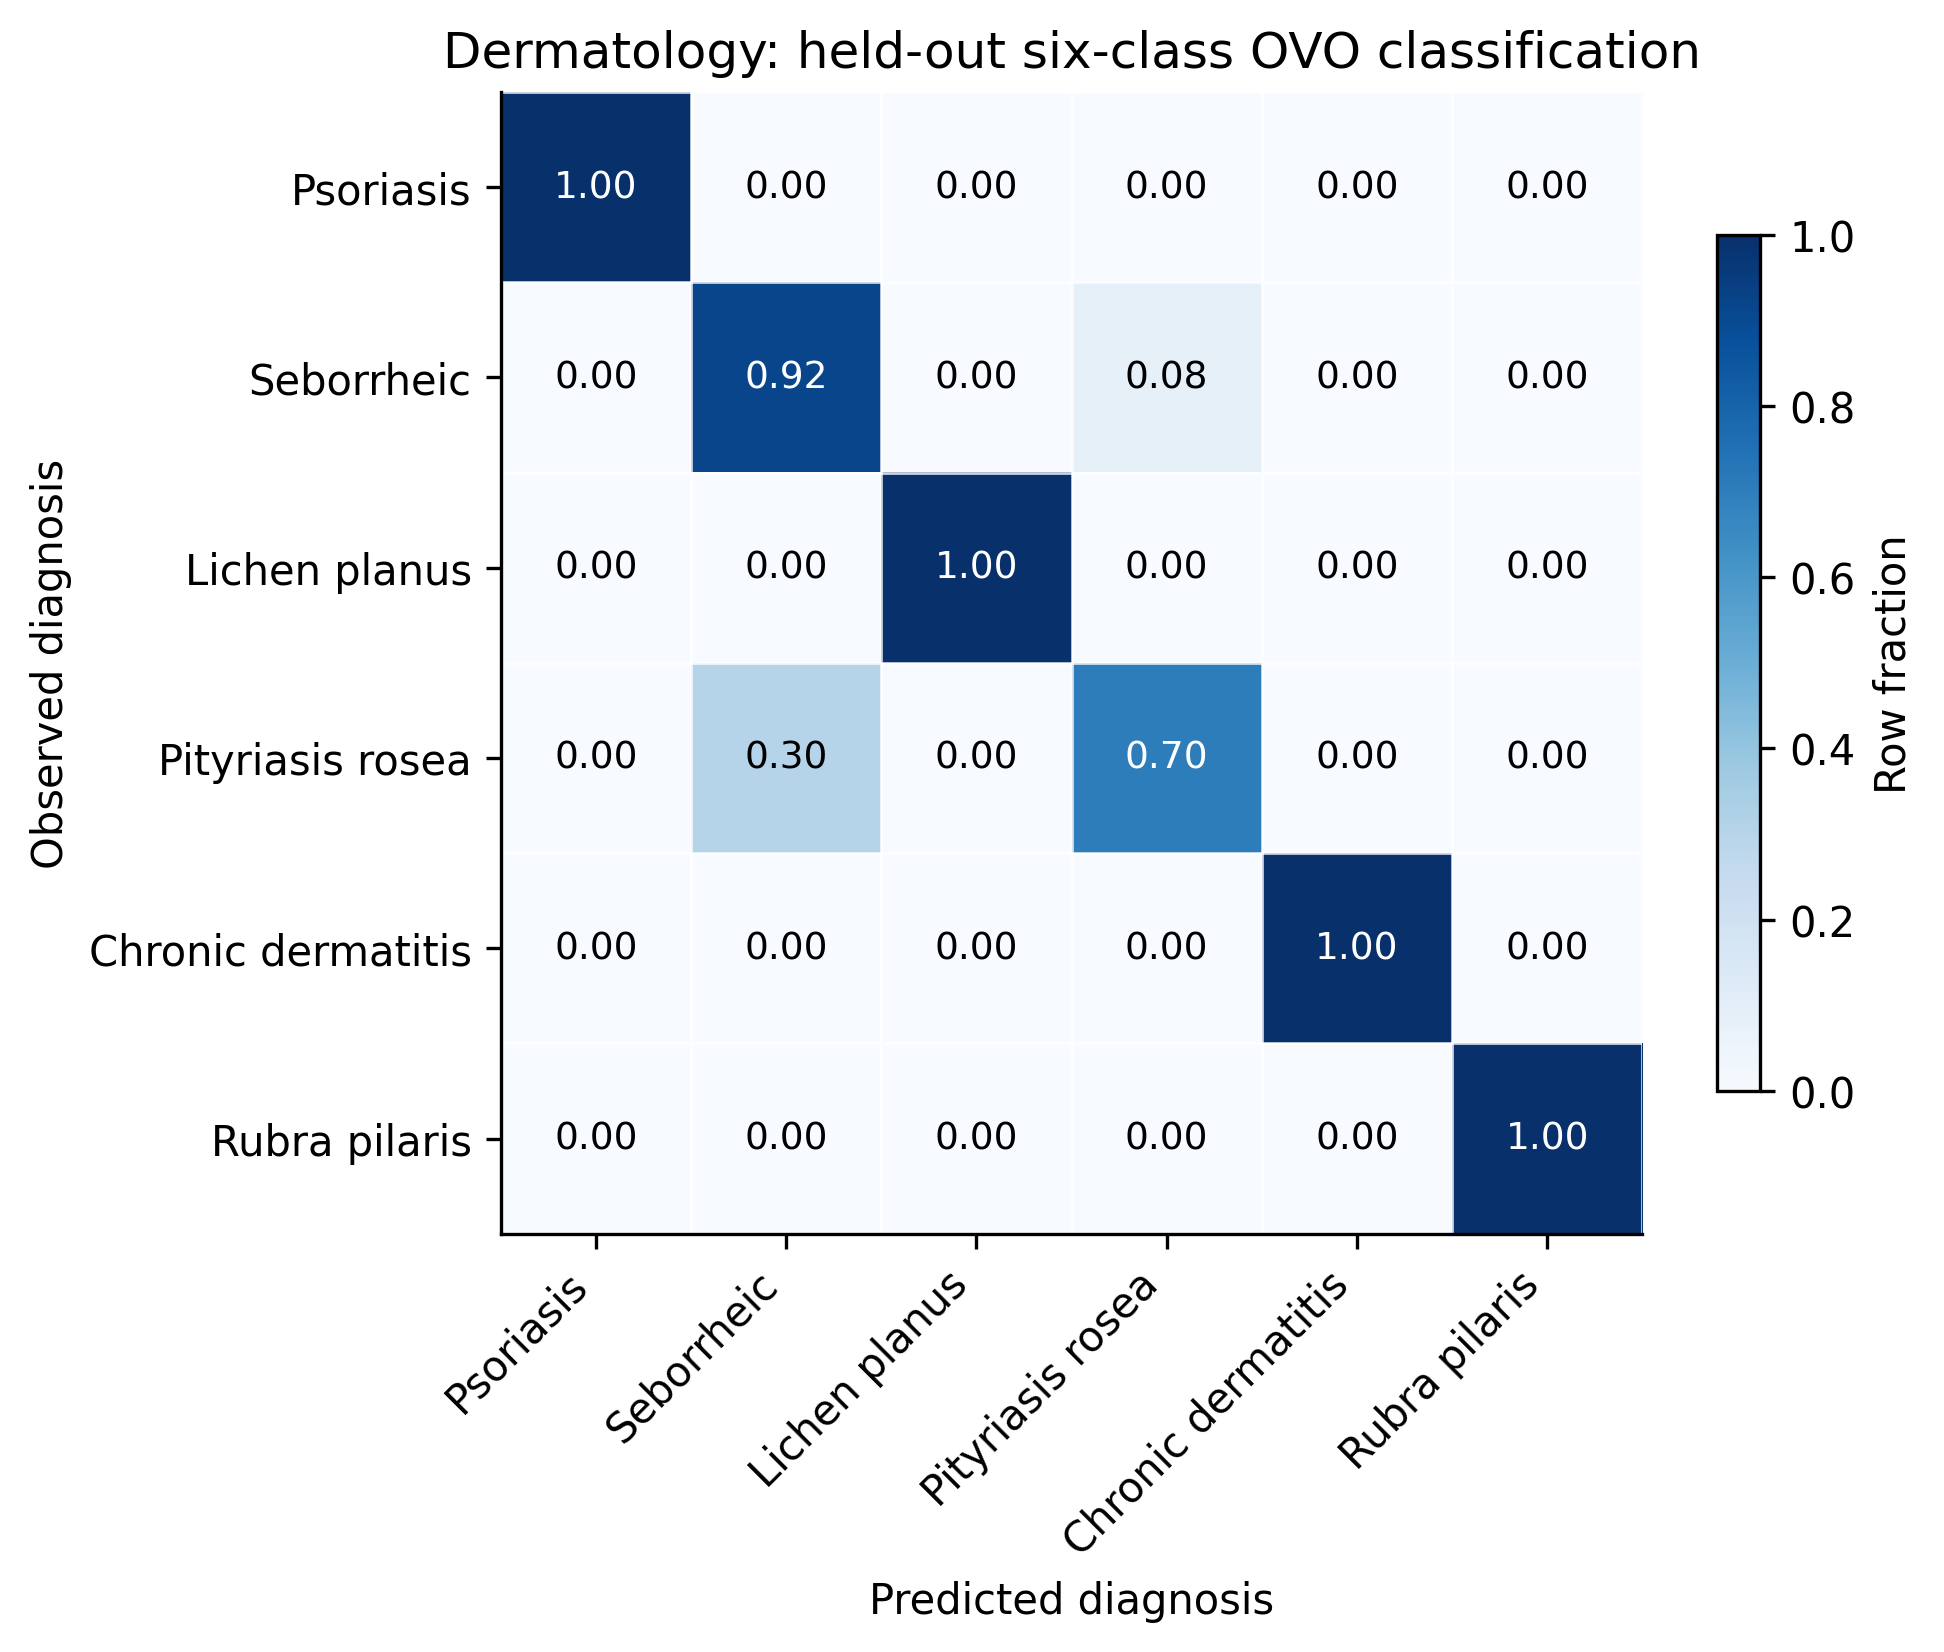

Normalized confusion matrix for the six-class OVO classifier on the held-out Dermatology test set. [Original figure](../Figures/Benchmark/06-%20Dermatology%20Confusion%20Row%20Normalized.png).

### NHANES regression

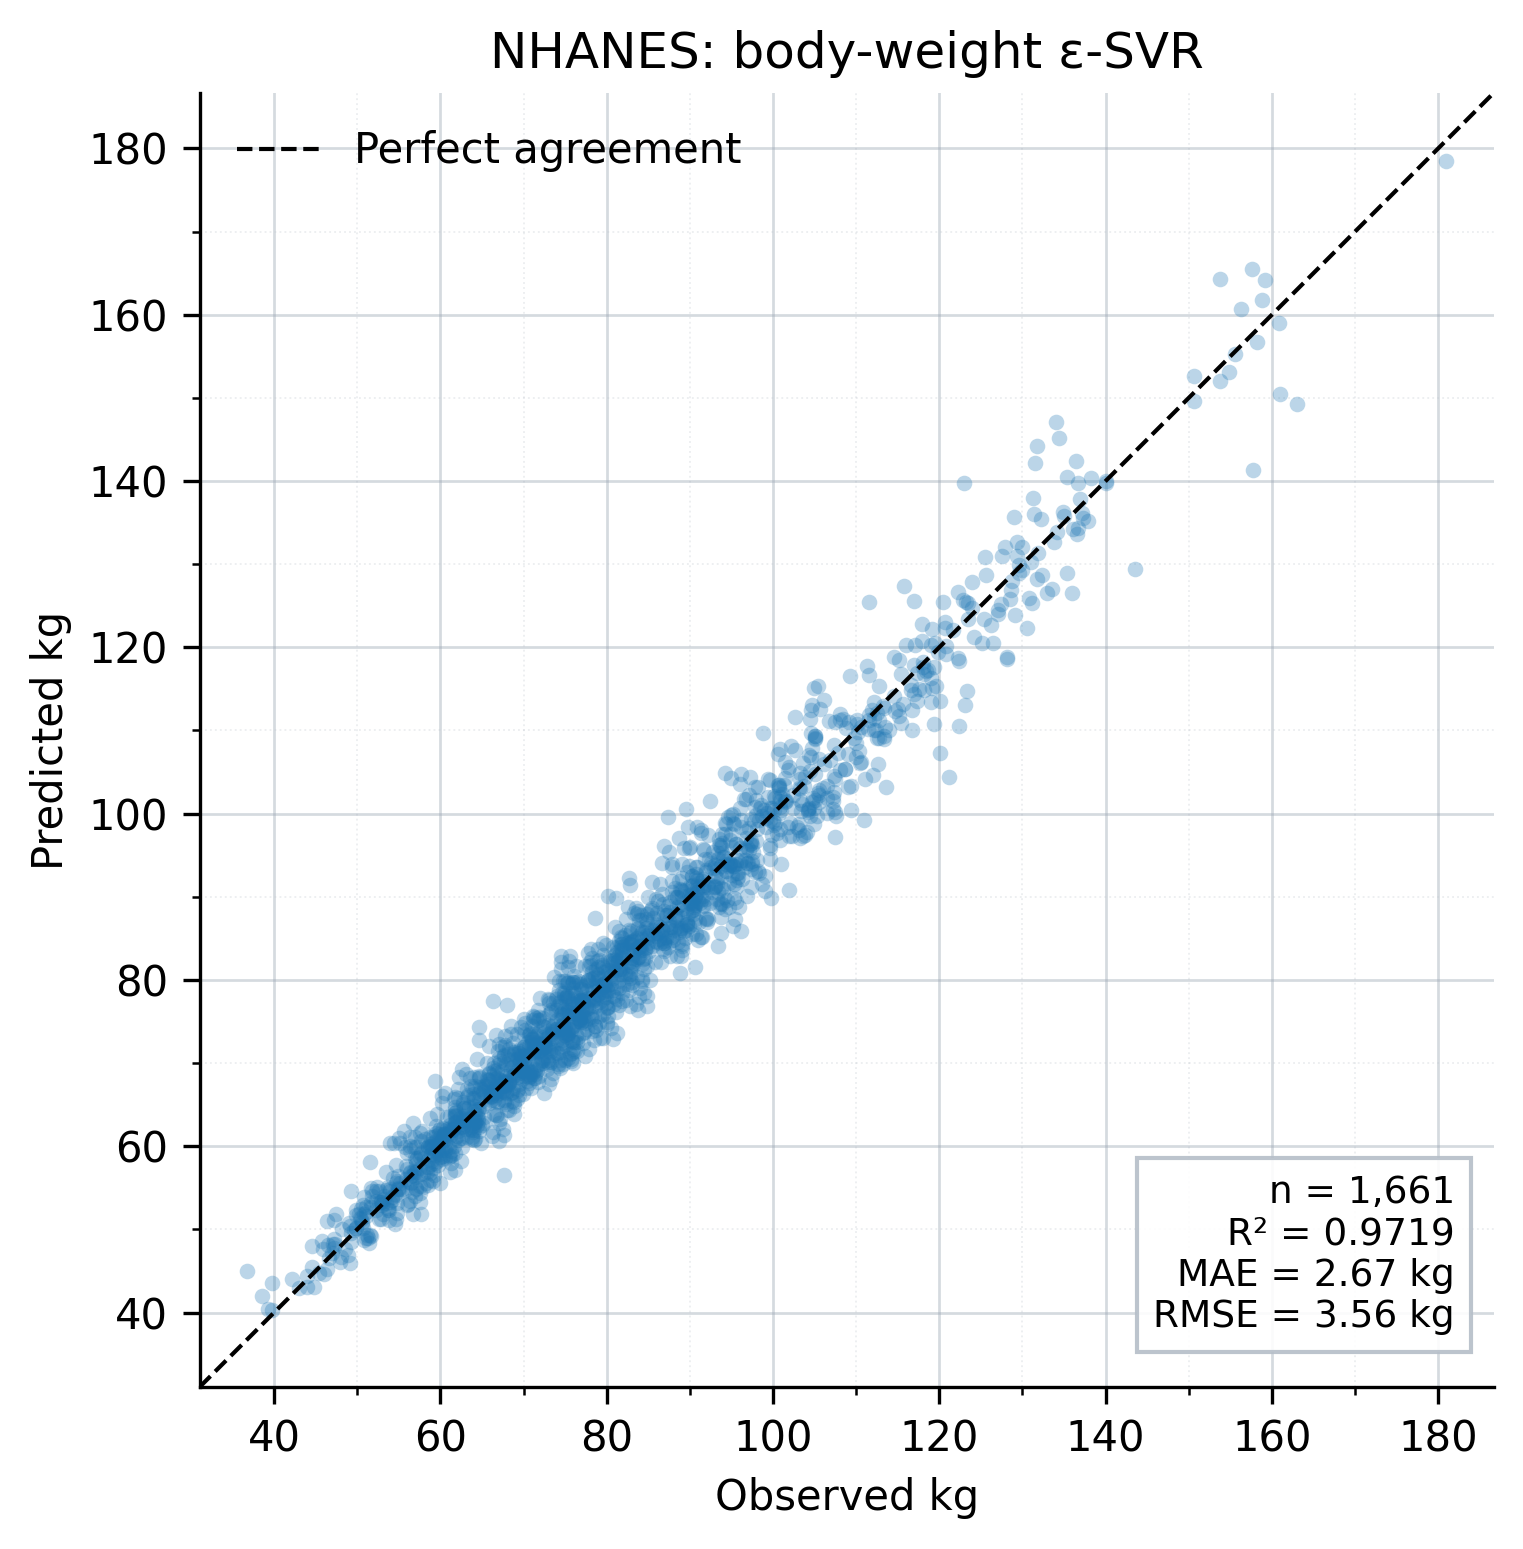

Observed and predicted body weights in the NHANES test partition. [Original figure](../Figures/Benchmark/06-%20NHANES%20Observed%20Versus%20Predicted.png).

### Optimization

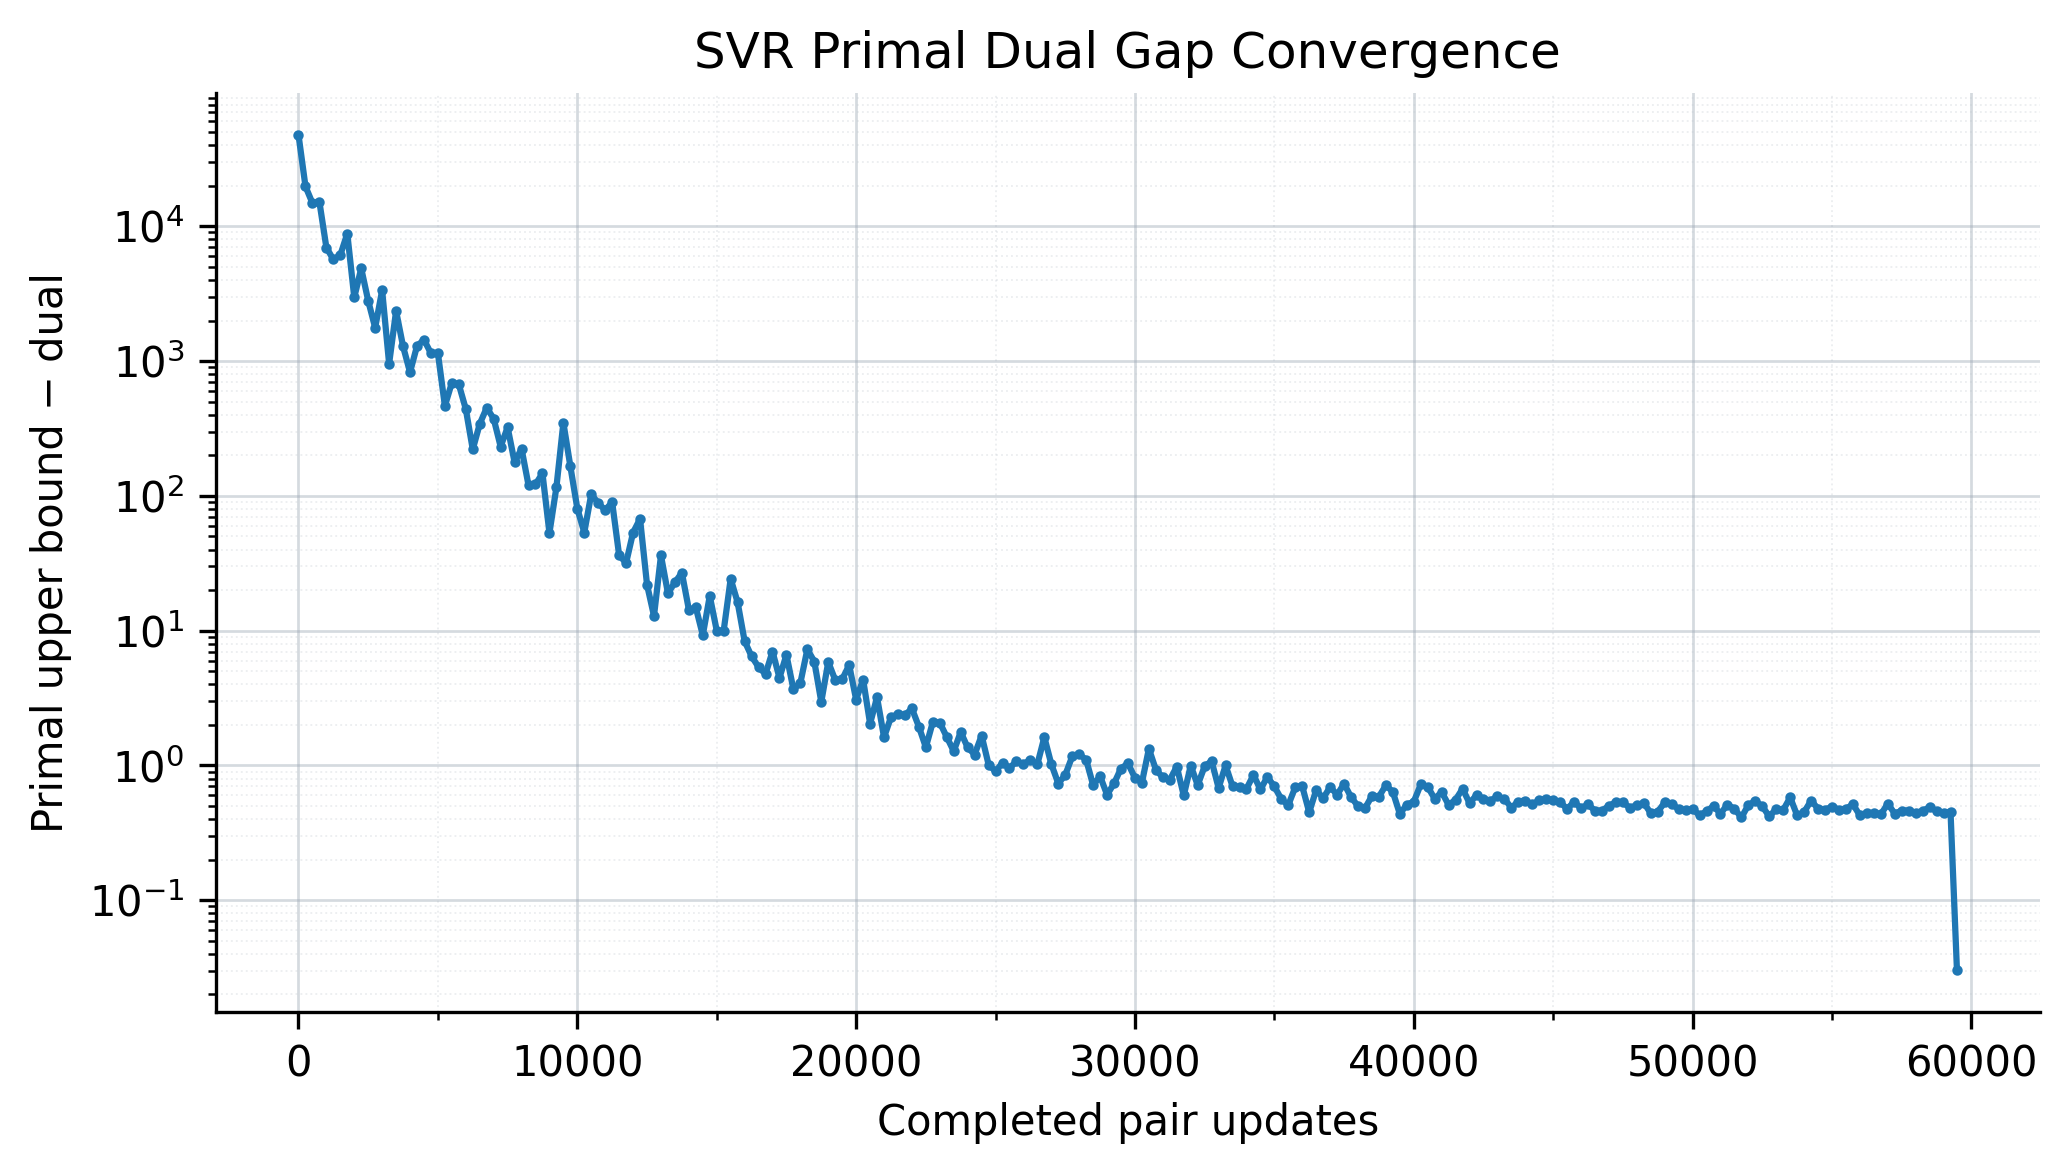

Primal–dual gap during SVR optimization. [Original figure](../Figures/Benchmark/06-%20SVR%20Primal%20Dual%20Gap%20Convergence.png).

### Temporal validation

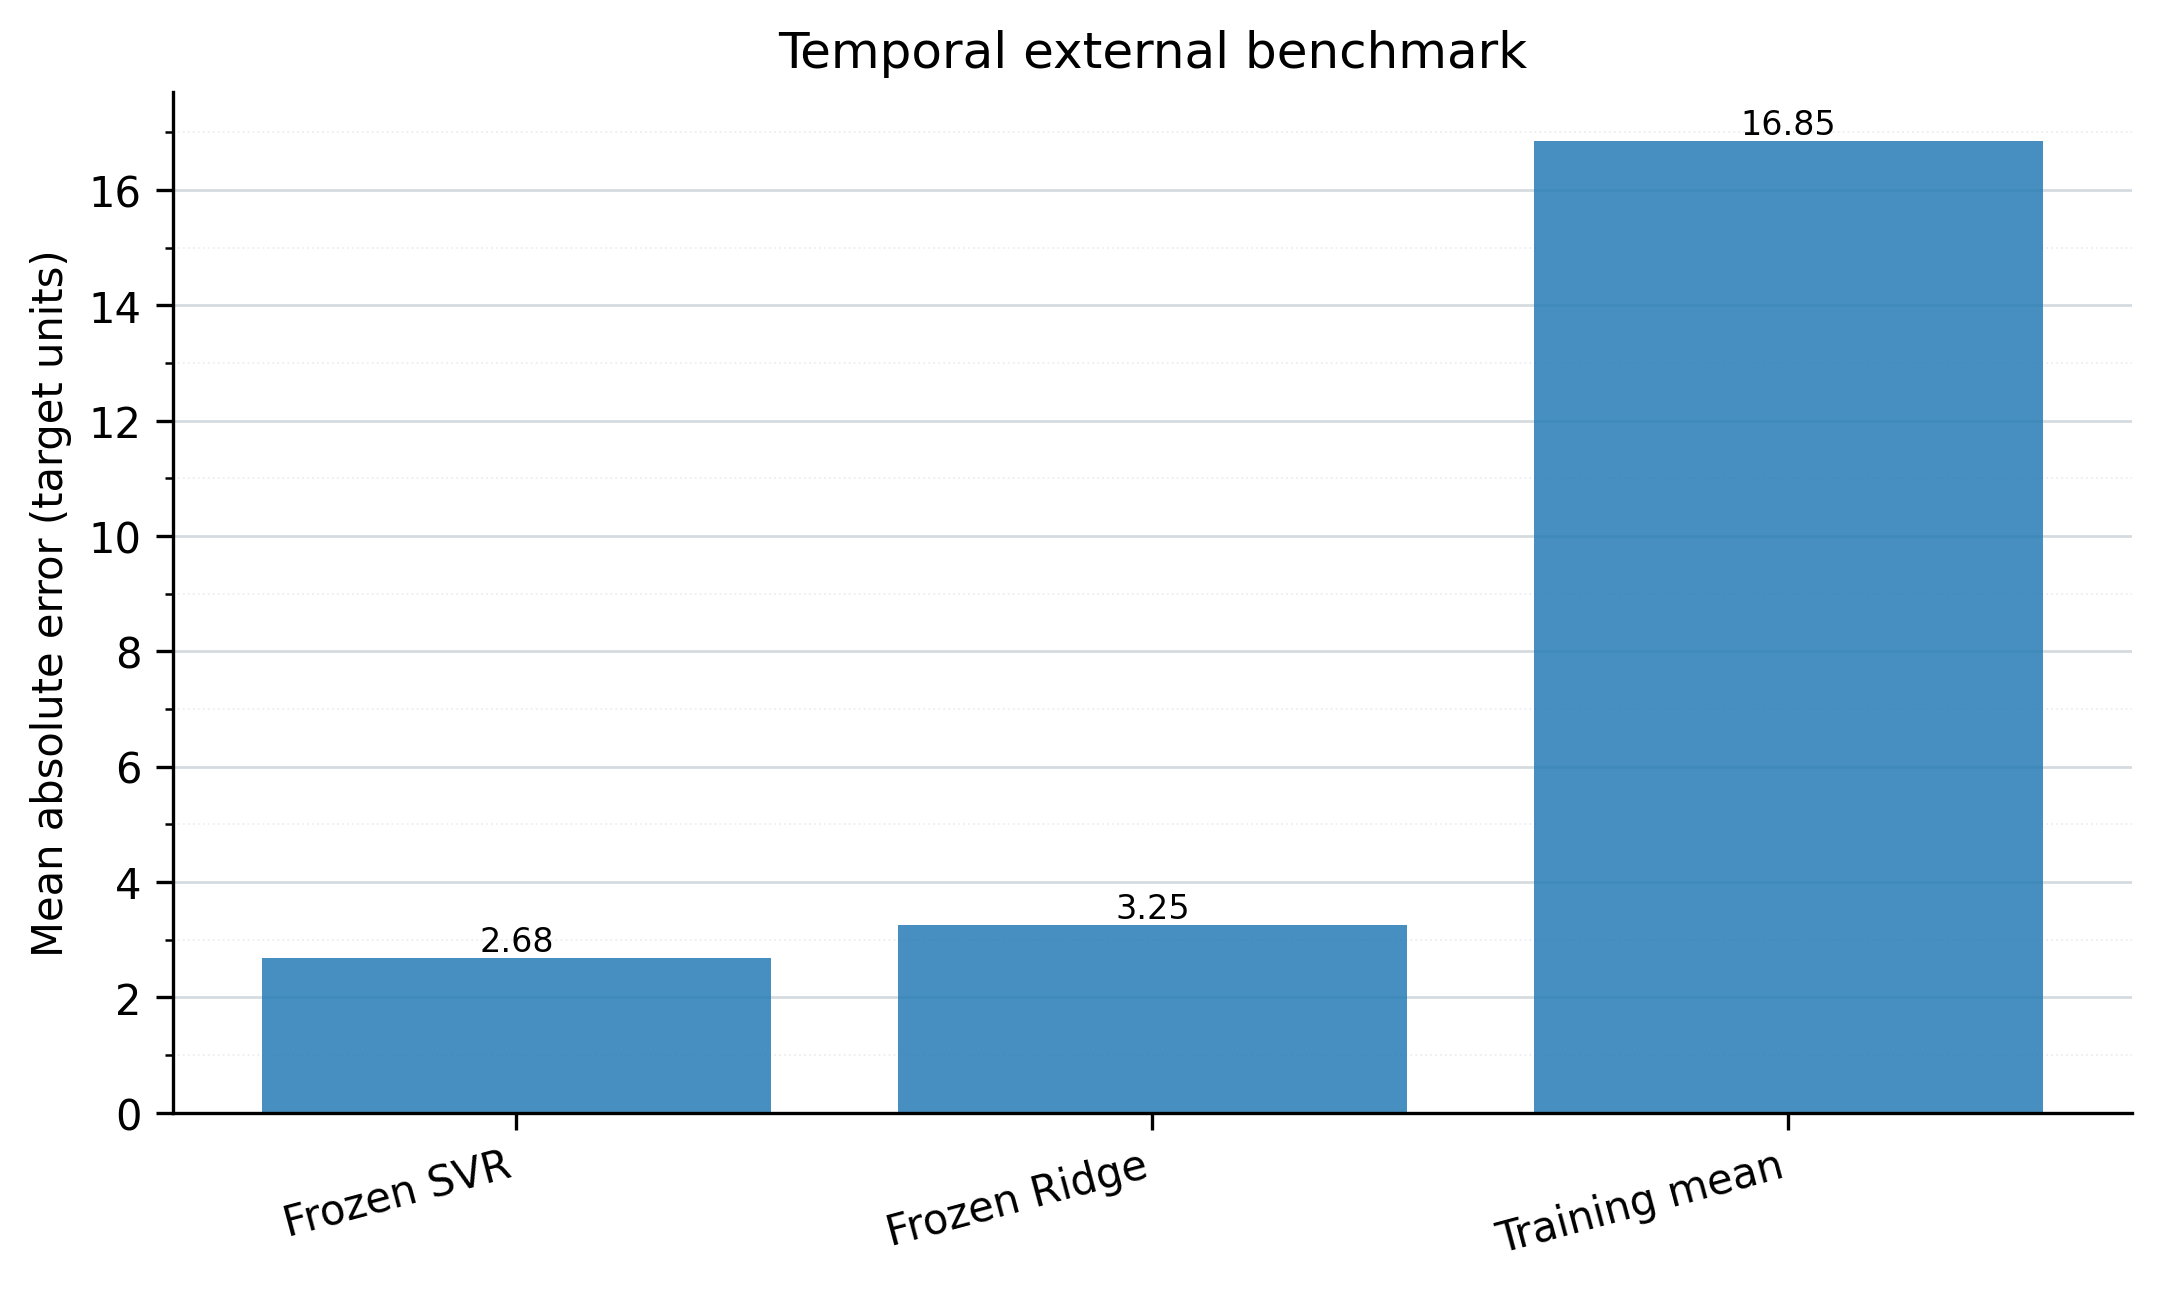

Model comparison on the subsequent NHANES 2021–2023 survey cycle. [Original figure](../Figures/Benchmark/06-%20NHANES%20External%20Model%20Comparison.png).

## Loading the algorithm implementations

The numbered notebooks provide the LP/QP routines, binary and kernel SVMs, multiclass extensions and ε-SVR. This cell loads their `algorithm`-tagged definitions into separate namespaces. Data, figures and results are stored in sibling directories of `Notebooks`.

In [ ]:
import base64
import csv
import gc
import hashlib
import importlib.metadata
import importlib.util
import io
import json
import math
import os
import platform
import random
import statistics
import struct
import sys
import time
import zlib
from bisect import bisect_left, bisect_right
from collections import Counter
from datetime import datetime, timezone
from itertools import product
from math import comb, fsum
from pathlib import Path
from statistics import NormalDist
from urllib.request import Request, urlopen
from uuid import uuid4
from zipfile import BadZipFile, ZipFile

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, Markdown, display
from tqdm.auto import tqdm

def locate_collection():
    """Locate the notebook and code folders from a project checkout."""
    def is_collection(path):
        return ((path / "Notebooks" / "01- Optimization And Duality.ipynb").is_file()
                and (path / "Code" / "report_evaluation.py").is_file())

    explicit = os.environ.get("SVM_SVR_ROOT")
    if explicit:
        path = Path(explicit).expanduser().resolve()
        if not is_collection(path):
            raise FileNotFoundError(f"Invalid SVM_SVR_ROOT: {path}")
        return path

    cwd = Path.cwd().resolve()
    for parent in (cwd, *cwd.parents):
        for path in (parent, parent / "Foundations", parent / "SVM-SVR" / "Foundations"):
            if is_collection(path):
                return path

    # Existing Colab projects can keep their files in Google Drive.
    try:
        from google.colab import drive
    except ImportError:
        drive = None
    if drive is not None:
        drive.mount("/content/drive")
        path = Path("/content/drive/MyDrive") / "Machine Learning" / "SVM-SVR"
        if is_collection(path):
            return path

    raise FileNotFoundError(
        "Start Jupyter in the project directory or set SVM_SVR_ROOT "
        "to the folder containing Notebooks and Code."
    )


def peak_rss_kib_linux():
    if sys.platform != "linux":
        return None
    import resource
    return resource.getrusage(resource.RUSAGE_SELF).ru_maxrss


COLLECTION = locate_collection()

NOTEBOOKS = COLLECTION / "Notebooks"
DATA = COLLECTION / "Data"
RESULTS = COLLECTION / "Results"
DATA.mkdir(exist_ok=True)
RESULTS.mkdir(exist_ok=True)

SOURCES = [
    "01- Optimization And Duality.ipynb",
    "02- Linear SVM.ipynb",
    "03- Kernel SVM.ipynb",
    "04- Multiclass SVM.ipynb",
    "05- Support Vector Regression.ipynb",
]
algorithm_namespaces = {}
source_hashes = {}
for filename in tqdm(SOURCES, desc="Loading algorithm notebooks", unit="file"):
    path = NOTEBOOKS / filename
    raw = path.read_bytes()
    source_hashes[filename] = hashlib.sha256(raw).hexdigest()
    document = json.loads(raw.decode("utf-8"))
    if document.get("nbformat") != 4:
        raise ValueError(f"Unsupported notebook format in {filename}")
    implementations = [cell for cell in document["cells"]
                       if cell["cell_type"] == "code"
                       and "algorithm" in cell.get("metadata", {}).get("tags", [])]
    if not implementations:
        raise ValueError(f"No algorithm cells in {filename}")
    algorithm_namespace = {"__builtins__": __builtins__, "__name__": "__main__"}
    for cell in implementations:
        source = "".join(cell["source"])
        exec(compile(source, str(path), "exec"), algorithm_namespace)
    algorithm_namespaces[filename] = algorithm_namespace

# Keep each notebook's helper functions in its own namespace.
classification_namespace = algorithm_namespaces[SOURCES[3]]
regression_namespace = algorithm_namespaces[SOURCES[4]]
Geometry = classification_namespace['Geometry']
RegressionGeometry = regression_namespace['Geometry']
assemble_category_boundaries = classification_namespace['assemble_category_boundaries']
assign_category_labels = classification_namespace['assign_category_labels']
construct_epsilon_tube = regression_namespace['construct_epsilon_tube']
measure_epsilon_tube = regression_namespace['measure_epsilon_tube']
print('Loaded five method notebooks.')


## Dermatology dataset

The [UCI Dermatology dataset](https://doi.org/10.24432/C5FK5P) (ID 33) contains 366 observations, 34 clinical and histopathological predictors, and six diagnostic categories. The loader uses a cached copy when available and otherwise retrieves the data from the documented sources.

In [ ]:
DATASETS = {
    "dermatology": {
        "filename": "Dermatology.data",
        "member": "dermatology.data",
        "official": "https://archive.ics.uci.edu/static/public/33/dermatology.zip",
        "mirror": "https://raw.githubusercontent.com/mikeizbicki/datasets/master/csv/uci/dermatology.data",
        "max_bytes": 200_000,
    },
}


def download_bytes(url, limit):
    request = Request(url, headers={"User-Agent": "SVM-SVR-Data-Validation/1.0"})
    with urlopen(request, timeout=35) as response:
        payload = response.read(limit + 1)
    if len(payload) > limit:
        raise ValueError(f"Download exceeded the {limit:,}-byte limit: {url}")
    return payload


def read_dataset(key):
    config = DATASETS[key]
    destination = DATA / config["filename"]
    if destination.is_file():
        content = destination.read_bytes()
        origin = "Existing cached dataset in Data"
    else:
        try:
            archive = download_bytes(config["official"], config["max_bytes"])
            with ZipFile(io.BytesIO(archive)) as bundle:
                members = [entry for entry in bundle.namelist()
                           if Path(entry).name == config["member"]]
                if len(members) != 1:
                    raise ValueError("The UCI archive has an unexpected directory layout.")
                content = bundle.read(members[0])
            origin = config["official"]
        except (OSError, ValueError, BadZipFile, EOFError) as error:
            # Try the mirror if the primary source is unavailable.
            print(f"Official UCI download failed for {key}: {type(error).__name__}: {error}")
            content = download_bytes(config["mirror"], config["max_bytes"])
            origin = config["mirror"]
        if not content or len(content) > config["max_bytes"]:
            raise ValueError(f"Unexpected dataset size for {key}.")
        destination.write_bytes(content)
    digest = hashlib.sha256(content).hexdigest()
    print(f"{key}: {len(content):,} bytes; SHA-256 {digest}; source: {origin}")
    return io.StringIO(content.decode("utf-8-sig")), {
        "path": str(destination), "sha256": digest, "source": origin,
        "bytes": len(content), "uci_archive": config["official"],
    }


dermatology_file, dermatology_provenance = read_dataset("dermatology")


## Reading the clinical variables

The source file contains eight missing values. Missing values are imputed using training-set medians after splitting.

In [ ]:
DERMATOLOGY_CLASSES = {
    1: "Psoriasis",
    2: "Seborrheic dermatitis",
    3: "Lichen planus",
    4: "Pityriasis rosea",
    5: "Chronic dermatitis",
    6: "Pityriasis rubra pilaris",
}


def parse_dermatology(file_object):
    X, y = [], []
    for line_number, row in enumerate(csv.reader(file_object), start=1):
        if not row:
            continue
        if len(row) != 35:
            raise ValueError(f"Dermatology row {line_number} has {len(row)} columns.")
        features = [None if token.strip() == "?" else float(token)
                    for token in row[:-1]]
        X.append(features)
        y.append(int(row[-1]))
    if len(X) != 366 or sorted(set(y)) != list(DERMATOLOGY_CLASSES):
        raise ValueError("Dermatology row count or class labels disagree with UCI metadata.")
    if sum(value is None for row in X for value in row) != 8:
        raise ValueError("Unexpected count of missing Dermatology values.")
    return X, y


derm_X, derm_y = parse_dermatology(dermatology_file)
print(f"Dermatology: {len(derm_X)} patients, 34 features, 6 classes.")


## Training, validation and test partitions

Class-stratified sampling assigns 219 observations to training, 72 to validation and 75 to testing. Imputation medians and scaling parameters are estimated from the training partition.

In [ ]:
SEED = 20261123


def stratified_three_way(labels, seed, train_fraction=0.60, val_fraction=0.20):
    rng = random.Random(seed)
    partitions = {"train": [], "val": [], "test": []}
    for label in sorted(set(labels)):
        indices = [i for i, item in enumerate(labels) if item == label]
        rng.shuffle(indices)
        n_train = round(len(indices) * train_fraction)
        n_val = round(len(indices) * val_fraction)
        if min(n_train, n_val, len(indices) - n_train - n_val) < 1:
            raise ValueError(f"Not enough observations in class {label}.")
        partitions["train"].extend(indices[:n_train])
        partitions["val"].extend(indices[n_train:n_train + n_val])
        partitions["test"].extend(indices[n_train + n_val:])
    for values in partitions.values():
        rng.shuffle(values)
    assert not (set(partitions["train"]) & set(partitions["val"]))
    assert not (set(partitions["train"]) & set(partitions["test"]))
    assert not (set(partitions["val"]) & set(partitions["test"]))
    return partitions


def fit_transform_parameters(training_rows):
    if not training_rows:
        raise ValueError("Empty training matrix.")
    columns = list(zip(*training_rows))
    medians = []
    means = []
    scales = []
    for column in columns:
        observed = [value for value in column if value is not None]
        if not observed:
            raise ValueError("Training feature contains only missing observations.")
        median = statistics.median(observed)
        cleaned = [median if value is None else value for value in column]
        mean = sum(cleaned) / len(cleaned)
        variance = sum((value - mean)**2 for value in cleaned) / len(cleaned)
        medians.append(median)
        means.append(mean)
        scales.append(math.sqrt(variance) if variance > 1e-14 else 1.0)
    return medians, means, scales


def apply_transform(rows, parameters):
    medians, means, scales = parameters
    transformed = []
    for row in rows:
        if len(row) != len(means):
            raise ValueError("Feature count differs from training data.")
        transformed.append([((medians[j] if value is None else value) - means[j])
                            / scales[j] for j, value in enumerate(row)])
    if any(not math.isfinite(value) for row in transformed for value in row):
        raise ValueError("Transformation produced nonfinite values.")
    return transformed


def select(values, indices):
    return [values[i] for i in indices]


derm_partitions = stratified_three_way(derm_y, SEED)
derm_parameters = fit_transform_parameters(select(derm_X, derm_partitions["train"]))
derm_scaled = {name: apply_transform(select(derm_X, indices), derm_parameters)
               for name, indices in derm_partitions.items()}
print(
    "Dermatology train/val/test:",
    *(len(derm_partitions[name]) for name in ("train", "val", "test"))
)


## Multiclass SVM

Two one-vs-one (OVO) configurations are evaluated using validation macro-F1: a linear kernel with $C=0.5$ and a Gaussian kernel with $C=1$ and $\sigma=5$. The selected configuration is applied to the test partition and also used to fit a one-vs-rest (OVR) ensemble. A majority-class classifier provides a reference for the effect of class imbalance.

## Evaluation utilities

The accompanying `report_evaluation.py` module contains the metric formulas and plotting routines. Each run has its own results and figure directories, with a record of the source-file hashes.

In [ ]:
report_source = COLLECTION / 'Code' / 'report_evaluation.py'
if not report_source.is_file():
    raise FileNotFoundError(f'Report module not found: {report_source}')
report_module_hash = hashlib.sha256(report_source.read_bytes()).hexdigest()
report_spec = importlib.util.spec_from_file_location('svm_svr_report_evaluation', report_source)
report_evaluation = importlib.util.module_from_spec(report_spec)
report_spec.loader.exec_module(report_evaluation)
RUN_ID = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ') + '-' + uuid4().hex[:8]
FIGURE_DIR = COLLECTION / 'Figures' / 'Runs' / RUN_ID
RUN_RESULTS = RESULTS / 'Runs' / RUN_ID
FIGURE_DIR.mkdir(parents=True, exist_ok=False)
report_artifacts = {}
print('Report metrics module verified:', report_module_hash)

def display_figures(paths):
    'Display the saved PNG files; keep the corresponding SVG files.'
    for path in paths:
        path = Path(path)
        if path.suffix.lower() == '.png':
            display(Markdown('**' + path.stem + '**'))
            display(Image(filename=str(path), width=800))


def show_table(title, table):
    display(Markdown('**' + title + '**'))
    display(table.style.format(precision=4, na_rep='N/A'))


def scalar_metrics_table(reports):
    return pd.DataFrame({name: {k: v for k, v in metrics.items()
                               if v is None or isinstance(v, (int, float))}
                         for name, metrics in reports.items()})


In [ ]:
def classification_metrics(truth, predicted, classes):
    if len(truth) != len(predicted) or not truth:
        raise ValueError("Nonempty, aligned predictions are required.")
    locations = {label: index for index, label in enumerate(classes)}
    matrix = [[0 for _ in classes] for _ in classes]
    for actual, guessed in zip(truth, predicted):
        matrix[locations[actual]][locations[guessed]] += 1
    precisions, recalls, f1s = [], [], []
    for i in range(len(classes)):
        tp = matrix[i][i]
        actual_total = sum(matrix[i])
        predicted_total = sum(row[i] for row in matrix)
        precision = tp / predicted_total if predicted_total else 0.0
        recall = tp / actual_total if actual_total else 0.0
        f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
        precisions.append(precision)
        recalls.append(recall)
        f1s.append(f1)
    return {"accuracy": sum(matrix[i][i] for i in range(len(classes))) / len(truth),
            "balanced_accuracy": sum(recalls) / len(recalls),
            "macro_f1": sum(f1s) / len(f1s),
            "recall_by_class": dict(zip(map(str, classes), recalls)),
            "confusion_matrix": matrix}


derm_start = time.perf_counter()
CLASSES = sorted(DERMATOLOGY_CLASSES)
y_derm_train = select(derm_y, derm_partitions["train"])
y_derm_val = select(derm_y, derm_partitions["val"])
y_derm_test = select(derm_y, derm_partitions["test"])

candidates = [
    ("Linear", {"kernel": "linear", "C": 0.5, "tol": 1e-3}),
    ("Gaussian", {"kernel": "rbf", "C": 1.0, "sigma": 5.0, "tol": 1e-3}),
]
classification_runs = []
for label, parameters in candidates:
    try:
        model = assemble_category_boundaries(
            derm_scaled["train"], y_derm_train, composition="pairwise",
            geometry=(Geometry("linear") if parameters["kernel"] == "linear"
                      else Geometry("radial", radial_width=parameters["sigma"])),
            penalty=parameters["C"], tolerance=parameters["tol"], progress=tqdm)
        validation = classification_metrics(
            y_derm_val, assign_category_labels(model, derm_scaled["val"]), CLASSES)
        classification_runs.append({"name": label, "parameters": parameters,
                                    "status": "converged", "validation": validation,
                                    "model": model})
        print(f"{label}: validation macro-F1={validation['macro_f1']:.3f}")
    except RuntimeError as error:
        classification_runs.append({"name": label, "parameters": parameters,
                                    "status": "failed", "error": str(error)})
        print(f"{label}: training failed: {error}")

valid_models = [entry for entry in classification_runs if entry["status"] == "converged"]
if not valid_models:
    raise RuntimeError("Neither classification specification met the solver stopping rule.")
selected_classifier = max(valid_models,
                          key=lambda entry: entry["validation"]["macro_f1"])
selected_parameters = selected_classifier["parameters"]
ovo_start = time.perf_counter()
ovo_timed_predictions = assign_category_labels(selected_classifier["model"], derm_scaled["test"])
derm_ovo_predict_seconds = time.perf_counter() - ovo_start
heldout_ovo = classification_metrics(y_derm_test, ovo_timed_predictions, CLASSES)

ovr = assemble_category_boundaries(
    derm_scaled["train"], y_derm_train, composition="class-against-rest",
    geometry=(Geometry("linear") if selected_parameters["kernel"] == "linear"
              else Geometry("radial", radial_width=selected_parameters["sigma"])),
    penalty=selected_parameters["C"], tolerance=selected_parameters["tol"], progress=tqdm)
derm_training_seconds = time.perf_counter() - derm_start - derm_ovo_predict_seconds
ovr_start = time.perf_counter()
ovr_timed_predictions = assign_category_labels(ovr, derm_scaled["test"])
derm_ovr_predict_seconds = time.perf_counter() - ovr_start
heldout_ovr = classification_metrics(y_derm_test, ovr_timed_predictions, CLASSES)
majority_class = Counter(y_derm_train).most_common(1)[0][0]
heldout_baseline = classification_metrics(
    y_derm_test, [majority_class] * len(y_derm_test), CLASSES)

ovo_kkt = [
    binary.stationarity_error for _, _, binary in selected_classifier["model"].component_boundaries
]
print("Selected kernel:", selected_classifier["name"])
print("OVO test accuracy / macro-F1:",
      f"{heldout_ovo['accuracy']:.3f}", f"{heldout_ovo['macro_f1']:.3f}")
print("OVR test accuracy / macro-F1:",
      f"{heldout_ovr['accuracy']:.3f}", f"{heldout_ovr['macro_f1']:.3f}")
print("Majority baseline macro-F1:", f"{heldout_baseline['macro_f1']:.3f}")
print("Maximum pairwise OVO KKT residual:", f"{max(ovo_kkt):.5g}")


## Classification performance by class

The confusion matrices show both counts and proportions within each true class. Precision, recall, F1, specificity, negative predictive value and the Jaccard index describe class-specific performance; MCC and Cohen's $\kappa$ summarize overall agreement. Wilson intervals quantify uncertainty in the observed proportions. The next section uses continuous decision scores to assess threshold-dependent performance.

In [ ]:
DERM_SHORT = ['Psoriasis', 'Seborrheic', 'Lichen planus', 'Pityriasis rosea',
            'Chronic dermatitis', 'Rubra pilaris']
derm_pred_ovo = assign_category_labels(selected_classifier['model'], derm_scaled['test'])
derm_pred_ovr = assign_category_labels(ovr, derm_scaled['test'])
DermReport = {
  'Custom OVO': report_evaluation.extended_classification(y_derm_test, derm_pred_ovo, CLASSES),
  'Custom OVR': report_evaluation.extended_classification(y_derm_test, derm_pred_ovr, CLASSES),
  'Majority baseline': report_evaluation.extended_classification(
      y_derm_test,
      [majority_class] * len(y_derm_test),
      CLASSES
  ),
}
assert abs(DermReport['Custom OVO']['accuracy'] - heldout_ovo['accuracy']) < 1e-12
assert abs(DermReport['Custom OVO']['macro_f1'] - heldout_ovo['macro_f1']) < 1e-12
report_artifacts['dermatology'] = []
for normalized, basename in [
    (False, '06- Dermatology Confusion Counts'),
    (True, '06- Dermatology Confusion Row Normalized')
]:
    report_artifacts['dermatology'] += report_evaluation.visualize_confusion(
        DermReport['Custom OVO']['confusion_matrix'], DERM_SHORT,
        'Dermatology: held-out six-class OVO classification', FIGURE_DIR, basename, normalize=normalized)
report_artifacts['dermatology'] += report_evaluation.visualize_per_class(
    DermReport['Custom OVO'], DERM_SHORT, 'Dermatology: precision, recall and F1 by class',
    FIGURE_DIR, '06- Dermatology Classwise Metrics')
report_artifacts['dermatology'] += report_evaluation.visualize_classification_bench(
    DermReport, 'Dermatology: SVM and majority baseline',
    FIGURE_DIR, '06- Dermatology Classification Comparison')
print('Dermatology expanded metrics:', {k: DermReport['Custom OVO'][k] for k in
      (
          'accuracy',
          'balanced_accuracy',
          'macro_f1',
          'weighted_f1',
          'multiclass_mcc',
          'cohen_kappa'
      )})
print('Dermatology report figures:', len(report_artifacts['dermatology']))

show_table('Dermatology — overall held-out metrics', scalar_metrics_table(DermReport))
show_table('Dermatology — OVO per-class metrics', pd.DataFrame.from_dict(
    DermReport['Custom OVO']['per_class'], orient='index').rename(index={
        str(k): v for k, v in DERMATOLOGY_CLASSES.items()
    }))
show_table('Dermatology — OVO confusion matrix (counts)', pd.DataFrame(
    DermReport['Custom OVO']['confusion_matrix'], index=DERM_SHORT, columns=DERM_SHORT))
show_table('Dermatology — accuracy Wilson 95% intervals', pd.DataFrame(
    {
        name: report['accuracy_wilson_95'] for name, report in DermReport.items()
    }, index=['Lower', 'Upper']))
display_figures(report_artifacts['dermatology'])


## ROC, precision–recall and classification uncertainty

The OVR curves use each binary classifier's signed decision scores. Pairwise OVO AUCs are calculated on the observations belonging to the corresponding class pair. The classwise tables include additional diagnostic ratios and intervals; McNemar's test compares the two ensembles on their paired test predictions.

In [ ]:
# Compute curves from signed decision scores.
mean = report_evaluation.mean
quantile = report_evaluation.quantile
advanced = {}

def save_advanced(fig, title, section):
    fig.tight_layout()
    paths = report_evaluation._write_figure(fig, FIGURE_DIR, '06- ' + title)
    plt.close(fig)
    report_artifacts.setdefault(section, []).extend(paths)
    display_figures(paths)

def binary_curves(positive, scores):
    c = report_evaluation.binary_score_curve(positive, scores)
    return c['fpr'], c['recall'], c['precision'], c['roc_auc'], c['average_precision']

def interval(values):
    return [quantile(values, .025), quantile(values, .975)]

def wilson(k, n):
    if not n:
        return [None, None]
    p = k / n
    z = 1.959963984540054
    d = 1 + z * z / n
    c = (p + z * z / (2 * n)) / d
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return [float(max(0, c - h)), float(min(1, c + h))]

truth = list(y_derm_test)
evaluate_margin = classification_namespace['evaluate_binary_boundary']
# OVR label 1 and the higher OVO label define the positive margin.
ovr_curves = {}
ranking = []
for target, _, boundary in tqdm(ovr.component_boundaries, desc='OVR decision scores'):
    score = evaluate_margin(boundary, derm_scaled['test'])
    assert tuple(boundary.labels) == (0, 1)
    curve = binary_curves([v == target for v in truth], score)
    ovr_curves[target] = curve
    ranking.append({
        'class': int(target),
        'support': int(sum([v == target for v in truth])),
        'auc': curve[3],
        'ap': curve[4]
    })
rank_frame = pd.DataFrame(ranking)
rank_summary = {key: mean([r[key] for r in ranking]) for key in ('auc', 'ap')}
rank_weighted = {key: sum(r[key] * r['support'] for r in ranking) / len(truth) for key in ('auc', 'ap')}
# Average the piecewise-linear ROC curves.
# Macro AUC is the mean of the classwise AUCs.
fig, ax = plt.subplots(figsize=(8, 5))
for k, (fpr, tpr, pr, auc, ap) in ovr_curves.items():
    ax.plot(fpr, tpr, label=f'{DERMATOLOGY_CLASSES[k]} ({auc:.3f})')
# Retain both endpoints of vertical ROC steps.
all_x = sorted({x for c in ovr_curves.values() for x in c[0]})
macro_left = []
macro_right = []
for x in all_x:
    left = []
    right = []
    for fpr, tpr, *_ in ovr_curves.values():
        equal = [i for i, v in enumerate(fpr) if v == x]
        if len(equal):
            left.append(tpr[equal[0]])
            right.append(tpr[equal[-1]])
        else:
            j = bisect_left(fpr, x)
            y = tpr[j - 1] + (tpr[j] - tpr[j - 1]) * (x - fpr[j - 1]) / (fpr[j] - fpr[j - 1])
            left.append(y)
            right.append(y)
    macro_left.append(mean(left))
    macro_right.append(mean(right))
macro_x = [x for x in all_x for _ in range(2)]
macro_y = [v for pair in zip(macro_left, macro_right) for v in pair]
assert abs(
    sum((macro_x[i] - macro_x[i - 1]) * (macro_y[i] + macro_y[i - 1]) / 2
        for i in range(1, len(macro_x))) - rank_summary['auc']
) < 1e-12
ax.plot(macro_x, macro_y, color='black', lw=2, ls='-.', label='Macro average')
ax.plot([0, 1], [0, 1], 'k--', lw=1, label='Chance')
ax.set(
    xlabel='False positive rate',
    ylabel='True positive rate',
    title=f'OVR ROC — macro AUC {rank_summary["auc"]:.3f}',
    xlim=(0, 1),
    ylim=(0, 1.03)
)
ax.legend(fontsize=8, loc='lower right', frameon=True)
save_advanced(fig, 'Dermatology Multiclass ROC', 'advanced_classification')
fig, ax = plt.subplots(figsize=(8, 5))
for k, (fpr, rec, pr, auc, ap) in ovr_curves.items():
    line, = ax.step(rec, pr, where='pre', label=f'{DERMATOLOGY_CLASSES[k]} ({ap:.3f})')
    ax.axhline(sum(v == k for v in truth) / len(truth), ls=':', lw=.7, color=line.get_color())
ax.set(
    xlabel='Recall',
    ylabel='Precision',
    title=f'OVR precision–recall — macro AP {rank_summary["ap"]:.3f}',
    xlim=(0, 1),
    ylim=(0, 1.03)
)
ax.legend(fontsize=8, loc='lower left', frameon=True)
save_advanced(fig, 'Dermatology Precision Recall', 'advanced_classification')
pairs = []
matrix_auc = [[float("nan")] * len(CLASSES) for _ in CLASSES]
for lo, hi, boundary in tqdm(
    selected_classifier['model'].component_boundaries,
    desc='OVO pairwise margins'
):
    assert tuple(boundary.labels) == (lo, hi)
    ix = [i for i, v in enumerate(truth) if v in (lo, hi)]
    scores = select(evaluate_margin(boundary, derm_scaled['test']), ix)
    c = binary_curves([truth[i] == hi for i in ix], scores)
    reverse = binary_curves([truth[i] == lo for i in ix], [-v for v in scores])
    i, j = CLASSES.index(lo), CLASSES.index(hi)
    matrix_auc[i][j] = matrix_auc[j][i] = c[3]
    pairs.append({
        'low': int(lo),
        'high': int(hi),
        'support': len(ix),
        'auc': c[3],
        'ap_high': c[4],
        'ap_low': reverse[4]
    })
fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(matrix_auc, vmin=0, vmax=1, cmap='Blues')
for i in range(len(CLASSES)):
    for j in range(len(CLASSES)):
        if i != j:
            ax.text(
                j, i,
                f'{matrix_auc[i][j]:.3f}',
                ha='center',
                va='center',
                color='white' if matrix_auc[i][j] > .65 else 'black'
            )
ax.set_xticks(range(6), DERM_SHORT, rotation=45, ha='right')
ax.set_yticks(range(6), DERM_SHORT)
ax.set_title('OVO pairwise AUC (test rows from each pair only)')
fig.colorbar(im, ax=ax)
save_advanced(fig, 'Dermatology Pairwise AUC Heatmap', 'advanced_classification')
# Stratified bootstrap of the test predictions.
rng = random.Random(20261125)
B = 2000
predictions = {'OVO': list(derm_pred_ovo), 'OVR': list(derm_pred_ovr)}
strata = [[i for i, v in enumerate(truth) if v == k] for k in CLASSES]
fboot = {name: [] for name in predictions}
for _ in tqdm(range(B), desc='Stratified classification bootstrap'):
    ix = [rng.choice(s) for s in strata for _ in s]
    for name, pred in predictions.items():
        fboot[name].append([2 * sum(truth[j] == k and pred[j] == k for j in ix) / max(
            1,
            sum(truth[j] == k for j in ix) + sum(pred[j] == k for j in ix)
        ) for k in CLASSES])
rows = []
for name, pred in predictions.items():
    for i, k in enumerate(CLASSES):
        a = [v == k for v in truth]
        b = [v == k for v in pred]
        tp = sum(x and y for x, y in zip(a, b))
        fp = sum(not x and y for x, y in zip(a, b))
        fn = sum(x and not y for x, y in zip(a, b))
        tn = sum(not x and not y for x, y in zip(a, b))
        p = tp / (tp + fp) if tp + fp else 0.
        r = tp / (tp + fn)
        sp = tn / (tn + fp)
        lrplus = r / (1 - sp) if sp < 1 else None
        lrminus = (1 - r) / sp if sp > 0 else None
        rows.append({
            'model': name,
            'class': int(k),
            'support': tp + fn,
            'precision': p,
            'recall': r,
            'specificity': sp,
            'f1': 2 * tp / (2 * tp + fp + fn),
            'f2': 5 * tp / (5 * tp + 4 * fn + fp),
            'f0.5': 1.25 * tp / (1.25 * tp + .25 * fn + fp),
            'gmean': float(math.sqrt(r * sp)),
            'youden_j': r + sp - 1,
            'lr_positive': lrplus,
            'lr_negative': lrminus,
            'diagnostic_odds_ratio': tp * tn / (fp * fn) if fp * fn else None,
            'precision_ci': wilson(tp, tp + fp),
            'recall_ci': wilson(tp, tp + fn),
            'f1_ci': interval([row[i] for row in fboot[name]])
        })
fig, axes = plt.subplots(1, 3, figsize=(13, 4.8), sharey=True)
for ax, metric in zip(axes, ['precision', 'recall', 'f1']):
    for offset, name in [(-.12, 'OVO'), (.12, 'OVR')]:
        subset = [r for r in rows if r['model'] == name]
        ys = [i + offset for i in range(6)]
        for y, r in zip(ys, subset):
            ax.plot(r[metric + '_ci'], [y, y], color='C0' if name == 'OVO' else 'C1')
            ax.scatter(r[metric], y, color='C0' if name == 'OVO' else 'C1', s=18)
        ax.scatter([], [], color='C0' if name == 'OVO' else 'C1', label=name)
    ax.set(xlim=(0, 1.05), xlabel=metric.upper() + ' (95% CI)')
    ax.legend(fontsize=8)
axes[0].set_yticks(range(6), DERM_SHORT)
axes[0].invert_yaxis()
fig.suptitle('Classwise uncertainty: Wilson precision/recall; stratified bootstrap F1')
save_advanced(fig, 'Dermatology Classwise Confidence Intervals', 'advanced_classification')
correct_a = [a == b for a, b in zip(predictions['OVO'], truth)]
correct_b = [a == b for a, b in zip(predictions['OVR'], truth)]
b = sum(a and not b for a, b in zip(correct_a, correct_b))
c = sum(not a and b for a, b in zip(correct_a, correct_b))
d = b + c
mcnemar = min(1., 2 * sum(comb(d, i) for i in range(min(b, c) + 1)) / 2**d) if d else 1.
advanced['classification'] = {
    'ovr_class_ranking': ranking,
    'ovr_macro': rank_summary,
    'ovr_weighted': rank_weighted,
    'ovo_pairs': pairs,
    'ovo_mean_pair_auc': mean([r['auc'] for r in pairs]),
    'classwise': rows,
    'mcnemar': {'ovo_only_correct': b, 'ovr_only_correct': c, 'p_exact': mcnemar},
    'bootstrap_replicates': B,
    'limitations': ('Uncalibrated margins; OVO pairwise and OVR classwise scores. Stratified intervals '
                    'condition on fitted models; undefined ratios are recorded as null.')
}
show_table('OVR class ranking scores', rank_frame.set_index('class'))
show_table(
    'OVR macro and weighted ranking',
    pd.DataFrame({'Macro': rank_summary, 'Weighted': rank_weighted})
)
show_table('OVO pairwise ranking', pd.DataFrame(pairs))
show_table(
    'Additional diagnostic metrics',
    pd.DataFrame(rows).drop(columns=['precision_ci', 'recall_ci', 'f1_ci'])
)
show_table('Paired exact McNemar test', pd.DataFrame([advanced['classification']['mcnemar']]))


## NHANES anthropometry

The regression target is measured body weight (`BMXWT`, kg). Six anthropometric measurements (height, arm length, leg length, arm circumference, hip circumference and waist circumference) and sex form the seven-dimensional input. BMI is excluded because it contains information derived from the target.

The two secondary CSV files for NHANES 2017–March 2020 contain 8,302 rows. Their published Git blob hashes identify the source files. The fixed partition assigns 6,641 rows to training and 1,661 to testing (seed 20261127); the split indices are embedded to reproduce both membership and order.

In [ ]:
# Read the two NHANES measurement files.

NHANES_DIR = DATA / "NHANES"
NHANES_DIR.mkdir(parents=True, exist_ok=True)
NHANES_SOURCES = {
    "female": (
        "nhanes_adult_female_bmx_2020.csv",
        "83adef2fdcbcb4dd484851ca6db7f477f9383135",
        4221
    ),
    "male": ("nhanes_adult_male_bmx_2020.csv", "d820fa76bc3ba31cf13bf3d9648464720208fe27", 4081),
}
NHANES_URL_PREFIX = "https://raw.githubusercontent.com/sudeepkumarhs/Multidimensional-Data/main/"
NHANES_COLS = ["BMXWT", "BMXHT", "BMXARML", "BMXLEG", "BMXARMC", "BMXHIP", "BMXWAIST"]
nhanes_observations = []
nhanes_source_audit = {}
for sex, (filename, blob_sha, expected_n) in tqdm(
    NHANES_SOURCES.items(),
    desc="NHANES source verification",
    unit="file"
):
    source_file = NHANES_DIR / filename
    if not source_file.exists():
        request = Request(
            NHANES_URL_PREFIX + filename,
            headers={"User-Agent": "SVM-SVR academic reproducibility"}
        )
        with urlopen(request, timeout=40) as response:
            retrieved = response.read()
        actual = hashlib.sha1(b"blob " + str(len(retrieved)).encode() + b"\0" + retrieved).hexdigest()
        if actual != blob_sha:
            raise ValueError("Upstream Git blob SHA-1 differs: " + filename)
        source_file.write_bytes(retrieved)
    raw = source_file.read_bytes()
    actual_sha = hashlib.sha1(b"blob " + str(len(raw)).encode() + b"\0" + raw).hexdigest()
    if actual_sha != blob_sha:
        raise ValueError("NHANES source check failed: " + filename)
    data_lines = [line for line in raw.decode("utf-8").splitlines()
                  if line.strip() and not line.lstrip().startswith("#")]
    header = next(csv.reader([data_lines[0]]))
    if header != NHANES_COLS:
        raise ValueError("Unexpected anthropometric columns: " + str(header))
    rows = [list(map(float, row)) for row in csv.reader(data_lines[1:])]
    if len(rows) != expected_n or any(len(row) != 7 or not all(math.isfinite(v) for v in row) for row in rows):
        raise ValueError("Wrong record count, feature count or nonfinite values")
    nhanes_observations.extend((row, 0 if sex == "female" else 1) for row in rows)
    nhanes_source_audit[sex] = {"rows": len(rows), "git_blob_sha1": actual_sha,
                                "sha256": hashlib.sha256(raw).hexdigest()}
assert len(nhanes_observations) == 8302
NHANES_X = [row[1:] + [sex] for row, sex in nhanes_observations]
NHANES_y = [row[0] for row, sex in nhanes_observations]
assert len(NHANES_X) == 8302 and all(len(row) == 7 and all(math.isfinite(v) for v in row) for row in NHANES_X)
# Fixed split indices (seed 20261127).
# Decode the ordered split indices from packed uint16 values.
_frozen_partition = (
    '...'
)
_packed = zlib.decompress(base64.b64decode(_frozen_partition))
assert hashlib.sha256(_packed).hexdigest() == '529a7e3fdb908a56a959fe25cf9607c33f747e1fbd78ca6d06634d0cfe608b16'
permutation = list(struct.unpack('<8302H', _packed))
assert sorted(permutation) == list(range(8302))
NHANES_test_index = permutation[:1661]
NHANES_train_index = permutation[1661:]
assert len(NHANES_train_index) == 6641 and not set(NHANES_train_index) & set(NHANES_test_index)
nhanes_raw_train = select(NHANES_X, NHANES_train_index)
nhanes_raw_test = select(NHANES_X, NHANES_test_index)
nhanes_train_targets = select(NHANES_y, NHANES_train_index)
# Calculate the training means and population standard deviations.
n_x_mean = [math.fsum(col) / len(col) for col in zip(*nhanes_raw_train)]
n_x_std = [
    math.sqrt(math.fsum((v - m)**2 for v in col) / len(col)) or 1.0 for col, m in zip(zip(*nhanes_raw_train), n_x_mean)
]
n_y_mean = math.fsum(nhanes_train_targets) / len(nhanes_train_targets)
n_y_std = math.sqrt(math.fsum((v - n_y_mean)**2 for v in nhanes_train_targets) / len(nhanes_train_targets))
def nhanes_scale(rows):
    return [[(v - m) / sd for v, m, sd in zip(row, n_x_mean, n_x_std)] for row in rows]
X_nhanes_train = nhanes_scale(nhanes_raw_train)
X_nhanes_test = nhanes_scale(nhanes_raw_test)
y_nhanes_train = [(v - n_y_mean) / n_y_std for v in nhanes_train_targets]
y_nhanes_test = select(NHANES_y, NHANES_test_index)
print("NHANES integrity:", nhanes_source_audit)
print('NHANES: 8,302 rows; 6,641 train; 1,661 test; 7 predictors (BMI excluded).')

## ε-SVR and regression baselines

The Gaussian-kernel SVR uses $C=10$, $\sigma=4$ and $\varepsilon=0.05$ on the standardized target. Feature and target scaling use training moments; predictions are transformed back to kilograms. A ridge regression fitted by solving the normal equations and a training-mean predictor provide the comparison models. The solver records its stationarity and primal–dual diagnostics alongside predictive errors.

In [ ]:
nhanes_spec = {"C": 10.0, "epsilon": 0.05, "sigma": 4.0, "precision": 1e-3, "update_budgets": 50}
nhanes_trace = []
t0 = time.perf_counter()
nhanes_tube = construct_epsilon_tube(
    X_nhanes_train, y_nhanes_train, geometry=RegressionGeometry(
        'radial',
        radial_width=nhanes_spec['sigma']
    ),
    penalty=nhanes_spec['C'], tube_width=nhanes_spec['epsilon'],
    precision=nhanes_spec['precision'], update_budgets=nhanes_spec['update_budgets'], progress=tqdm, trace=nhanes_trace)
nhanes_custom_seconds = time.perf_counter() - t0
if not nhanes_tube.certified:
    raise RuntimeError('SVR convergence checks failed.')
predict_start = time.perf_counter()
nhanes_custom = [v * n_y_std + n_y_mean for v in measure_epsilon_tube(
    nhanes_tube,
    X_nhanes_test,
    progress=tqdm
)]
nhanes_predict_seconds = time.perf_counter() - predict_start

# Solve the ridge normal equations.
# Leave the intercept unpenalized.
def solve_linear_system(matrix, rhs):
    """Gaussian elimination with partial pivoting and backward substitution."""
    a = [list(row) + [float(v)] for row, v in zip(matrix, rhs)]
    n = len(a)
    for j in range(n):
        pivot = max(range(j, n), key=lambda i: abs(a[i][j]))
        a[j], a[pivot] = a[pivot], a[j]
        if abs(a[j][j]) < 1e-14:
            raise ValueError('Singular normal equations')
        for i in range(j + 1, n):
            factor = a[i][j] / a[j][j]
            a[i][j] = 0.
            for k in range(j + 1, n + 1):
                a[i][k] -= factor * a[j][k]
    x = [0.] * n
    for i in range(n - 1, -1, -1):
        x[i] = (a[i][-1] - math.fsum(a[i][j] * x[j] for j in range(i + 1, n))) / a[i][i]
    return x

linear_train = [[1.] + row for row in X_nhanes_train]
linear_test = [[1.] + row for row in X_nhanes_test]
columns = list(zip(*linear_train))
normal_matrix = [
    [
        math.fsum(u * v for u, v in zip(a, b)) + (1.0 if i == j and i != 0 else 0.) for j, b in enumerate(columns)
    ] for i, a in enumerate(columns)
]
normal_rhs = [math.fsum(u * v for u, v in zip(col, nhanes_train_targets)) for col in columns]
linear_coefficients = solve_linear_system(normal_matrix, normal_rhs)
nhanes_ridge_pred = [math.fsum(
    a * b for a, b in zip(row, linear_coefficients)
) for row in linear_test]
nhanes_mean_pred = [n_y_mean] * len(NHANES_test_index)

def nhanes_score(observed, predicted):
    report = report_evaluation.extended_regression(
        observed,
        predicted,
        target_units='kg',
        thresholds=[2, 5, 10]
    )
    return {'r2': report['r2'], 'mae_kg': report['mae'], 'rmse_kg': report['rmse']}

nhanes_evaluation = {
    'custom': nhanes_score(y_nhanes_test, nhanes_custom),
    'ridge': nhanes_score(y_nhanes_test, nhanes_ridge_pred),
    'train_mean': nhanes_score(y_nhanes_test, nhanes_mean_pred),
}
nhanes_solver_audit = {'certified': bool(nhanes_tube.certified),
    'kkt_error': float(nhanes_tube.kkt_error), 'stationarity_gap': float(nhanes_tube.stationarity_gap),
    'primal_dual_gap': float(nhanes_tube.primal_value - nhanes_tube.dual_value),
    'relative_gap': float(nhanes_tube.relative_gap),
    'support_vector_count': len(nhanes_tube.retained_examples),
    'pair_updates': int(nhanes_tube.updates),
    'training_seconds': float(nhanes_custom_seconds)}
# Check the benchmark performance thresholds.
nhanes_go = (nhanes_tube.certified and nhanes_evaluation['custom']['r2'] >= 0.90
           and nhanes_evaluation['custom']['mae_kg'] < nhanes_evaluation['train_mean']['mae_kg'])
print('NHANES SVR test:', nhanes_evaluation)
print('NHANES numerical diagnostics:', nhanes_solver_audit)
print('Benchmark criteria met:', nhanes_go)


## Regression performance

The observed-versus-predicted and residual plots complement $R^2$, absolute and squared-error measures, and correlation and concordance statistics. All reported weight errors are in kilograms unless expressed as percentages or dimensionless ratios.

In [ ]:
NHANES_REPORT = {
    'Custom ε-SVR': report_evaluation.extended_regression(y_nhanes_test, nhanes_custom,
                      training_sd=n_y_std, thresholds=[2, 5, 10], target_units='kg'),
    'Direct ridge': report_evaluation.extended_regression(y_nhanes_test, nhanes_ridge_pred,
                      training_sd=n_y_std, thresholds=[2, 5, 10], target_units='kg'),
    'Training mean': report_evaluation.extended_regression(y_nhanes_test, nhanes_mean_pred,
                      training_sd=n_y_std, thresholds=[2, 5, 10], target_units='kg'),
}
assert abs(NHANES_REPORT['Custom ε-SVR']['r2'] - nhanes_evaluation['custom']['r2']) < 1e-12
report_artifacts['nhanes'] = []
report_artifacts['nhanes'] += report_evaluation.visualize_observed_predicted(
    y_nhanes_test, nhanes_custom, 'NHANES: body-weight ε-SVR', 'kg',
    FIGURE_DIR, '06- NHANES Observed Versus Predicted')
report_artifacts['nhanes'] += report_evaluation.visualize_residuals(
    y_nhanes_test, nhanes_custom, 'NHANES: weight residual diagnostics', 'kg',
    FIGURE_DIR, '06- NHANES Regression Residuals')
report_artifacts['nhanes'] += report_evaluation.visualize_regression_bench(
    NHANES_REPORT, 'NHANES: holdout MAE versus train-only controls',
    FIGURE_DIR, '06- NHANES Regression Comparison')
print('NHANES extended metrics:', {k: NHANES_REPORT['Custom ε-SVR'][k] for k in
      (
          'r2',
          'mae',
          'rmse',
          'bias_prediction_minus_observed',
          'pearson_r',
          'spearman_rho',
          'lin_concordance'
      )})

show_table('NHANES — held-out regression metrics', scalar_metrics_table(NHANES_REPORT))
show_table('NHANES — absolute error within threshold (fraction)', pd.DataFrame(
    {name: metrics['absolute_error_within'] for name, metrics in NHANES_REPORT.items()}))
show_table(
    'NHANES — solver diagnostics',
    pd.DataFrame.from_dict(nhanes_solver_audit, orient='index', columns=['Value'])
)
display_figures(report_artifacts['nhanes'])


## Agreement, calibration and error distribution

Bland–Altman limits, calibration slope and intercept, absolute-error quantiles and empirical error distributions characterize agreement. The relative errors RAE and RRSE use the training-mean predictor as their denominator; Gaussian MMD² compares the marginal observed and predicted distributions. A paired bootstrap estimates uncertainty in the MAE difference between the fitted SVR and ridge models.

In [ ]:
# Regression diagnostics for the fitted models.
variance = report_evaluation.variance
dot = report_evaluation.dot
actual = list(y_nhanes_test)
reg_predictions = {
    'SVR': list(nhanes_custom),
    'Ridge': list(nhanes_ridge_pred),
    'Mean': list(nhanes_mean_pred)
}
reg_errors = {name: [x - y for x, y in zip(p, actual)] for name, p in reg_predictions.items()}
reg_extra = {}
baseline_error = reg_errors['Mean']
bandwidth = float(n_y_std)

def mmd2(a, b, h):
    # Biased empirical Gaussian MMD².
    def kernel_mean(x, y):
        return math.fsum(math.exp(-.5 * ((u - v) / h)**2) for u in x for v in y) / (len(x) * len(y))
    return max(0., kernel_mean(a, a) + kernel_mean(b, b) - 2 * kernel_mean(a, b))

mean_actual = mean(actual)
for name, p in tqdm(reg_predictions.items(), desc='Regression agreement metrics'):
    e = reg_errors[name]
    mu = mean(e)
    sd = math.sqrt(variance(e, 1))
    pm = mean(p)
    centered = [v - pm for v in p]
    slope = dot(
        centered,
        [v - mean_actual for v in actual]
    ) / dot(centered, centered) if max(p) - min(p) > 1e-10 else None
    reg_extra[name] = {
        'rae_train_mean': sum(map(abs, e)) / sum(map(abs, baseline_error)),
        'rrse_train_mean': math.sqrt(dot(e, e) / dot(baseline_error, baseline_error)),
        'bias': mu,
        'loa_lower': mu - 1.96 * sd,
        'loa_upper': mu + 1.96 * sd,
        'calibration_slope': slope,
        'calibration_intercept': mean_actual - slope * pm if slope is not None else None,
        'mmd2_gaussian': mmd2(actual, p, bandwidth)
    }
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
for ax, name in zip(axes, ['SVR', 'Ridge']):
    e = reg_errors[name]
    m = reg_extra[name]
    ax.scatter([(a + b) / 2 for a, b in zip(actual, reg_predictions[name])], e, s=6, alpha=.35)
    for key, ls in [('bias', '-'), ('loa_lower', '--'), ('loa_upper', '--')]:
        ax.axhline(m[key], ls=ls, color='C1', label=f'{key}: {m[key]:.2f}')
    ax.set(title=name, xlabel='Mean of measured and predicted (kg)')
    ax.legend(fontsize=8)
axes[0].set_ylabel('Predicted − measured (kg)')
fig.suptitle('Descriptive Bland–Altman agreement')
save_advanced(fig, 'NHANES Bland Altman', 'advanced_regression')
fig, ax = plt.subplots(figsize=(7, 5))
normal = NormalDist()
q = [normal.inv_cdf((i + .5) / len(actual)) for i in range(len(actual))]
for name in ['SVR', 'Ridge']:
    e = reg_errors[name]
    mean_e = mean(e)
    sd_e = math.sqrt(variance(e, 1))
    ax.plot(q, sorted((v - mean_e) / sd_e for v in e), '.', ms=2, label=name)
ax.plot(q, q, 'k--', lw=1)
ax.set(
    xlabel='Normal theoretical quantile',
    ylabel='Standardized residual quantile',
    title='Residual Q–Q'
)
ax.legend()
save_advanced(fig, 'NHANES Residual QQ', 'advanced_regression')
fig, ax = plt.subplots(figsize=(7, 5))
for name, e in reg_errors.items():
    ax.step(
        [0] + sorted(map(abs, e)),
        [i / len(e) for i in range(len(e) + 1)],
        where='post',
        label=name
    )
ax.set(
    xlabel='Absolute error (kg)',
    ylabel='Fraction at or below threshold',
    title='Absolute error ECDF'
)
ax.legend()
ax.axvline(5, ls=':', color='0.4', lw=.8)
save_advanced(fig, 'NHANES Absolute Error ECDF', 'advanced_regression')
fig, ax = plt.subplots(figsize=(7, 5))
lo = float(min(actual))
hi = float(max(actual))
ax.plot([lo, hi], [lo, hi], 'k--', label='Ideal')
for name in ['SVR', 'Ridge']:
    p = reg_predictions[name]
    order = sorted(range(len(p)), key=lambda i: p[i])
    bins = [order[i * len(p) // 10:(i + 1) * len(p) // 10] for i in range(10)]
    ax.plot(
        [mean(select(p, ix)) for ix in bins],
        [mean(select(actual, ix)) for ix in bins],
        'o-',
        label=name
    )
ax.set(
    xlabel='Mean predicted weight (kg)',
    ylabel='Mean observed weight (kg)',
    title='Regression calibration (10 equal-count bins)',
    xlim=(lo, hi),
    ylim=(lo, hi)
)
ax.set_aspect('equal', adjustable='box')
ax.legend()
save_advanced(fig, 'NHANES Regression Calibration', 'advanced_regression')
# Compute Tukey boxplot statistics.
def error_box(name, errors):
    a = sorted(map(abs, errors))
    q1, med, q3 = [quantile(a, q) for q in (.25, .5, .75)]
    iqr = q3 - q1
    low = min(v for v in a if v >= q1 - 1.5 * iqr)
    high = max(v for v in a if v <= q3 + 1.5 * iqr)
    return {
        'label': name,
        'q1': q1,
        'med': med,
        'q3': q3,
        'whislo': low,
        'whishi': high,
        'fliers': [v for v in a if v < low or v > high]
    }
boxes = [error_box(name, e) for name, e in reg_errors.items()]
fig, axes = plt.subplots(1, 2, figsize=(10, 4.6))
axes[0].bxp(boxes, showfliers=True)
axes[0].set(ylabel='Absolute error (kg)', title='All models, full range')
axes[1].bxp(boxes[:2], showfliers=True)
axes[1].set(ylabel='Absolute error (kg)', title='SVR and Ridge detail')
fig.suptitle('Absolute error distribution — Tukey whiskers')
save_advanced(fig, 'NHANES Error Boxplot', 'advanced_regression')
sex = [row[-1] for row in nhanes_raw_test]
edges = [quantile(nhanes_train_targets, q) for q in (.2, .4, .6, .8)]
weight_bin = [bisect_right(edges, v) for v in actual]
subgroup = []
for variable, groups, labels in [
    ('Sex', sex, ['Female', 'Male']),
    ('Weight quintile (training cutoffs)', weight_bin, ['Q1', 'Q2', 'Q3', 'Q4', 'Q5'])
]:
    subset = []
    for idx, label in enumerate(labels):
        ix = [i for i, v in enumerate(groups) if v == idx]
        for name, e in reg_errors.items():
            if ix:
                row = {
                    'grouping': variable,
                    'group': label,
                    'model': name,
                    'n': len(ix),
                    'mae': mean([abs(e[i]) for i in ix]),
                    'rmse': math.sqrt(mean([e[i]**2 for i in ix])),
                    'bias': mean(select(e, ix))
                }
                subgroup.append(row)
                subset.append(row)
    fig, axes = plt.subplots(1, 3, figsize=(12, 4))
    x = list(range(len(labels)))
    for ax, key in zip(axes, ['mae', 'rmse', 'bias']):
        for off, name in [(-.18, 'SVR'), (.18, 'Ridge')]:
            lookup = {r['group']: r[key] for r in subset if r['model'] == name}
            ax.bar(
                [v + off for v in x],
                [lookup.get(l, float("nan")) for l in labels],
                .33,
                label=name
            )
        ax.set_xticks(x, labels)
        ax.set_ylabel(key.upper() + ' (kg)')
        ax.axhline(0, color='k', lw=.6)
        ax.legend(fontsize=8)
    fig.suptitle(variable + ' — descriptive subgroup errors')
    save_advanced(
        fig,
        'NHANES ' + ('Sex Specific Errors' if variable == 'Sex' else 'Weight Dependent Errors'),
        'advanced_regression'
    )
# Resample the same rows for both models.
rng = random.Random(20261126)
boot = {name: [] for name in ['SVR', 'Ridge']}
for _ in tqdm(range(B), desc='Paired regression bootstrap'):
    ix = rng.choices(range(len(actual)), k=len(actual))
    a = select(actual, ix)
    sst = variance(a) * len(a)
    for name in boot:
        e = select(reg_errors[name], ix)
        ss = dot(e, e)
        boot[name].append([1 - ss / sst, mean(list(map(abs, e))), math.sqrt(ss / len(e))])
ci_rows = []
for name, values in boot.items():
    e = reg_errors[name]
    points = [
        1 - dot(e, e) / (variance(actual) * len(actual)),
        mean(list(map(abs, e))),
        math.sqrt(dot(e, e) / len(e))
    ]
    for j, key in enumerate(['R2', 'MAE', 'RMSE']):
        ci_rows.append({
            'model': name,
            'metric': key,
            'point': float(points[j]),
            'ci': interval([row[j] for row in values])
        })
fig, axes = plt.subplots(1, 3, figsize=(10, 3.5))
for ax, key in zip(axes, ['R2', 'MAE', 'RMSE']):
    for i, r in enumerate([v for v in ci_rows if v['metric'] == key]):
        ax.plot(r['ci'], [i, i], lw=2)
        ax.scatter(r['point'], i)
    ax.set_yticks([0, 1], ['SVR', 'Ridge'])
    ax.set_xlabel(key)
fig.suptitle('Fixed-model row-bootstrap 95% intervals')
save_advanced(fig, 'NHANES Bootstrap Confidence Intervals', 'advanced_regression')
delta = [a[1] - b[1] for a, b in zip(boot['SVR'], boot['Ridge'])]
delta_ci = interval(delta)
delta_point = mean([abs(a) - abs(b) for a, b in zip(reg_errors['SVR'], reg_errors['Ridge'])])
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(delta, bins=35)
ax.axvline(0, color='k', ls='--')
ax.axvline(delta_point, color='C1', label='Observed difference')
for end in delta_ci:
    ax.axvline(end, color='C1', ls=':')
ax.set(
    xlabel='MAE(SVR) − MAE(Ridge), kg',
    ylabel='Bootstrap count',
    title='Paired bootstrap difference (negative favors SVR)'
)
ax.legend()
save_advanced(fig, 'NHANES Paired Bootstrap Delta MAE', 'advanced_regression')
advanced['regression'] = {
    'additional_metrics': reg_extra,
    'subgroups': subgroup,
    'weight_cutoffs_kg': edges,
    'bootstrap_ci': ci_rows,
    'paired_delta_mae': {'point': delta_point, 'ci': delta_ci},
    'bootstrap_replicates': B,
    'mmd_bandwidth_kg': bandwidth,
    'limitations': ('Fixed-model row bootstrap assumes exchangeability. Subgroup, agreement and calibration '
                    'statistics are descriptive.')
}
show_table('Additional regression metrics', pd.DataFrame(reg_extra))
show_table('Subgroup diagnostics', pd.DataFrame(subgroup))
show_table(
    'Row-bootstrap confidence intervals',
    pd.DataFrame(ci_rows).assign(
        lower=[r['ci'][0] for r in ci_rows],
        upper=[r['ci'][1] for r in ci_rows]
    ).drop(columns='ci')
)
show_table(
    'Paired ΔMAE',
    pd.DataFrame([{'point': delta_point, 'lower': delta_ci[0], 'upper': delta_ci[1]}])
)


## Optimization diagnostics

SVR stationarity and objective values are sampled every 250 pair updates and at termination. An intermediate intercept is used to calculate the diagnostic primal upper bound. The plots also summarize support-vector coefficients, the proportion of support vectors and computational time.

In [ ]:
# Plot the recorded SVR optimization history.
trace = pd.DataFrame(nhanes_trace)
assert len(trace) > 1 and trace.iloc[-1]['updates'] == nhanes_tube.updates
for key, title, ylabel, log in [
    ('stationarity_gap', 'KKT Convergence', 'Feasible signed-gradient gap', True),
    ('dual', 'Dual Objective Convergence', 'Dual objective', False),
    ('gap', 'Primal Dual Gap Convergence', 'Primal upper bound − dual', True)
]:
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.plot(
        trace['updates'],
        [max(v, 1e-15) for v in trace[key]] if log else trace[key],
        '.-',
        ms=3
    )
    if log:
        ax.set_yscale('log')
    if key == 'stationarity_gap':
        ax.axhline(nhanes_spec['precision'], color='C1', ls='--', label='Stopping tolerance')
        ax.legend()
    ax.set(xlabel='Completed pair updates', ylabel=ylabel, title='SVR ' + title)
    save_advanced(fig, 'SVR ' + title, 'optimization')
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].bar(['SVM\nOVO selection + OVR', 'SVR'], [derm_training_seconds, nhanes_custom_seconds])
axes[0].set_ylabel('Seconds')
axes[0].set_title('Training')
axes[1].bar(
    ['OVO', 'OVR', 'SVR'],
    [derm_ovo_predict_seconds, derm_ovr_predict_seconds, nhanes_predict_seconds]
)
axes[1].set_ylabel('Seconds')
axes[1].set_title('Held-out prediction')
fig.suptitle('Wall-clock timing, different sample counts')
save_advanced(fig, 'Computational Performance', 'optimization')
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(nhanes_tube.signed_weights, bins=50)
ax.set(
    xlabel='Signed dual coefficient α − α*',
    ylabel='Support vectors',
    title='SVR retained coefficient distribution'
)
save_advanced(fig, 'SVR Support Vector Coefficient Distribution', 'optimization')
sv_rows = []
for name, model in [('OVO', selected_classifier['model']), ('OVR', ovr)]:
    for low, high, boundary in model.component_boundaries:
        denom = sum(y == low or y == high for y in y_derm_train) if name == 'OVO' else len(y_derm_train)
        sv_rows.append({
            'model': name,
            'component': f'{low}-{high}' if high is not None else str(low),
            'support_vectors': len(boundary.retained_examples),
            'training_rows': denom,
            'ratio': len(boundary.retained_examples) / denom
        })
sv_rows.append({
    'model': 'SVR',
    'component': 'NHANES',
    'support_vectors': len(nhanes_tube.retained_examples),
    'training_rows': len(X_nhanes_train),
    'ratio': len(nhanes_tube.retained_examples) / len(X_nhanes_train)
})
fig, ax = plt.subplots(figsize=(11, 4))
x = list(range(len(sv_rows)))
ax.bar(
    x,
    [r['ratio'] for r in sv_rows],
    color=[{'OVO': 'C0', 'OVR': 'C1', 'SVR': 'C2'}[r['model']] for r in sv_rows]
)
ax.set_xticks(x, [r['model'] + ' ' + r['component'] for r in sv_rows], rotation=60, ha='right')
ax.set(
    ylabel='Fraction of component training rows',
    ylim=(0, 1.05),
    title='Support vector ratios by fitted component'
)
save_advanced(fig, 'Support Vector Ratio', 'optimization')
advanced['optimization'] = {
    'svr_history': nhanes_trace,
    'support_vectors': sv_rows,
    'timings_seconds': {
        'derm_training_and_validation': derm_training_seconds,
        'ovo_prediction': derm_ovo_predict_seconds,
        'ovr_prediction': derm_ovr_predict_seconds,
        'svr_training': nhanes_custom_seconds,
        'svr_prediction': nhanes_predict_seconds
    },
    'history_note': ('The trace uses the median residual intercept until termination. The gap uses a primal '
                     'upper bound and may be nonmonotonic; the KKT curve shows signed-gradient stationarity.')
}
show_table('Support vector ratios', pd.DataFrame(sv_rows))
show_table('Numerical history endpoints', trace.iloc[[0, -1]])
show_table('Measured execution times', pd.DataFrame([advanced['optimization']['timings_seconds']]))


## Comparison with an earlier NHANES run

The following check compares the current scores, data hashes and solver specification with the earlier NHANES result. The archived and current metrics differ slightly in MAE and RMSE following the change to standard-library preprocessing; the original values remain available in the comparison record.

In [ ]:
nhanes_result_path = RESULTS / "nhanes_baseline.json"
nhanes_record = {
    'status': 'complete',
    'dataset': 'CDC NHANES body measures: secondary public CSV, 2017–March 2020',
    'sample_count': 8302, 'training_rows': 6641, 'heldout_rows': 1661,
    'source_sha256_and_git_blobs': nhanes_source_audit,
    'feature_names': NHANES_COLS[1:] + ['sex'], 'excluded_derived_features': ['BMI'],
    'target': 'BMXWT (body weight, kg)', 'split_seed': 20261127,
    'split_unit': 'CSV row, no verified participant identifiers',
    'solver_spec': nhanes_spec, 'source_notebooks_sha256': source_hashes,
    'solver_audit': nhanes_solver_audit, 'prediction_metrics': nhanes_evaluation,
    'go_criterion_satisfied': bool(nhanes_go),
    'interpretation': 'Exploratory body-weight prediction from anthropometry.',
    'limitations': ['The cohort was screened during model development.',
       'Participant IDs are unavailable in the secondary CSVs.',
       'Anthropometric predictors are closely related to body mass.',
       'Ridge coefficients use the normal equations.']}
reference_fields = [('sample_count',), ('training_rows',), ('heldout_rows',),
    ('source_sha256_and_git_blobs',), ('feature_names',), ('excluded_derived_features',),
    ('target',), ('split_seed',), ('solver_spec',), ('solver_audit', 'certified'),
    ('prediction_metrics', 'custom', 'r2'), ('prediction_metrics', 'custom', 'mae_kg'),
    ('prediction_metrics', 'custom', 'rmse_kg')]
def nested_value(obj, keys):
    for key in keys:
        obj = obj[key]
    return obj
comparison = {'archive': str(nhanes_result_path.relative_to(COLLECTION)), 'status': 'ARCHIVE_MISSING', 'differences': []}
if nhanes_result_path.is_file():
    historical = json.loads(nhanes_result_path.read_text(encoding='utf-8'))
    comparison['archive_sha256'] = hashlib.sha256(nhanes_result_path.read_bytes()).hexdigest()
    comparison['source_notebook_hashes_match'] = historical.get('source_notebooks_sha256') == source_hashes
    for keys in reference_fields:
        try:
            old, new = nested_value(historical, keys), nested_value(nhanes_record, keys)
            equal = (math.isclose(float(old), float(new), rel_tol=1e-5, abs_tol=1e-5)
                   if isinstance(old, (int, float)) and not isinstance(old, bool) and isinstance(new, (int, float)) else old == new)
        except KeyError:
            old, new = None, None
            equal = False
        if not equal:
            comparison['differences'].append({
                'field': '.'.join(keys),
                'previous': old,
                'current': new
            })
    comparison['status'] = 'MATCH' if not comparison['differences'] else 'DIFFERENCE_REQUIRES_REVIEW'
print('NHANES historical comparison:', comparison)


## Saving the benchmark results

The primary report contains the evaluation metrics, model diagnostics, data and source hashes, and paths to the corresponding figures. The figures are displayed in the notebook and stored as PNG and SVG.

In [ ]:
assert sum(len(v) for v in report_artifacts.values()) == 52, 'Expected 26 PNG/SVG pairs'
assert all(Path(p).is_file() and Path(p).stat().st_size > 0 for paths in report_artifacts.values() for p in paths)
report_registry = {
 'status': 'complete',
 'run_id': RUN_ID, 'solver': 'SVM and SVR implementations in notebooks 01–05',
 'report_module_sha256': report_module_hash, 'method_source_sha256': source_hashes,
 'source_data_sha256': {
     'Dermatology': dermatology_provenance['sha256'],
     'NHANES': nhanes_source_audit
 },
 'dermatology_classification': DermReport, 'nhanes_regression': NHANES_REPORT,
 'nhanes_record': nhanes_record, 'historical_comparison': comparison,
 'advanced_assessment': advanced,
 'numerical_dependencies': ('Python standard library only; pandas, Matplotlib, IPython, tqdm and Colab are '
                            'presentation/runtime utilities'),
 'frozen_partition_sha256': hashlib.sha256(_packed).hexdigest(),
 'bootstrap_rng': 'Python random.Random; fixed seeds 20261125 and 20261126',
 'figure_files': {
     key: [str(Path(x).relative_to(COLLECTION)) for x in paths] for key, paths in report_artifacts.items()
 },
 'limitations': ['Exploratory Dermatology holdout.', 'NHANES row-level split; participant IDs unavailable.',
 'NHANES cohort screened during development.']}
RUN_RESULTS.mkdir(parents=True, exist_ok=True)
result_report_path = RUN_RESULTS / 'benchmark_metrics.json'
payload = json.dumps(report_registry, indent=2, ensure_ascii=False, allow_nan=False) + '\n'
if result_report_path.exists():
    if result_report_path.read_text(encoding='utf-8') != payload:
        raise RuntimeError('Report differs from the saved run; start a new run.')
else:
    with result_report_path.open('x', encoding='utf-8') as stream:
        stream.write(payload)
print('Dermatology Accuracy:', DermReport['Custom OVO']['accuracy'])
print('NHANES R²:', NHANES_REPORT['Custom ε-SVR']['r2'])
print(
    'NHANES certification:',
    nhanes_tube.certified,
    'historical comparison:',
    comparison['status']
)
print('Saved:', result_report_path)
print('Report figures:', {key: len(v) for key, v in report_artifacts.items()})

show_table('Final benchmark summary', pd.DataFrame([
    {
        'Dataset': 'Dermatology',
        'Model': 'SVM (OVO)',
        'Metric': 'Accuracy',
        'Score': DermReport['Custom OVO']['accuracy']
    },
    {
        'Dataset': 'NHANES',
        'Model': 'ε-SVR',
        'Metric': 'R²',
        'Score': NHANES_REPORT['Custom ε-SVR']['r2']
    },
]).set_index('Dataset'))
display(Markdown('**Historical numerical comparison:** ' + comparison['status']))


# Numerical and statistical validation

The following experiments address numerical correctness, sensitivity to the training partition and the behavior of the fitted models. Dermatology analyses use the 291 development observations, comprising the original training and validation sets. The initial NHANES sensitivity experiments use a seeded subset of 1,200 training rows; some of the more expensive perturbation experiments use 250 rows. Full five-fold validation of all 6,641 development rows follows later.

## Analytical solutions and numerical stress tests

Small problems with known LP, QP, SVM and SVR solutions are used to check the implementations. Additional fixtures test Gram matrix symmetry and positive semidefiniteness, dual feasibility, SVM complementary slackness, repeated observations, near-singular cases, extreme parameters and invalid inputs.

In [ ]:
# Analytical and numerical test fixtures.
VALIDATION_SEED = 20261128
validation = {'protocol': {'seed': VALIDATION_SEED, 'status': 'Exploratory development-set analysis',
                           'nhanes_secondary_rows': 1200, 'permutations': 19,
                           'full_nhanes_cv': False, 'dermatology_outer_folds': 5, 'inner_folds': 3, 'dermatology_cv_repeats': 2},
              'environment': {
                  'process_peak_rss_before_extension_kib_linux': peak_rss_kib_linux(),
                  'python': sys.version, 'platform': platform.platform(),
                  'cpu_count': os.cpu_count(),
                  'presentation_versions': {p: importlib.metadata.version(p) for p in [
                      'pandas',
                      'matplotlib',
                      'tqdm',
                      'ipython'
                  ]}}}
checks = []
def check(name, fn):
    try:
        detail = fn()
        checks.append({'test': name, 'status': 'PASS', 'detail': str(detail)})
    except Exception as exc:
        checks.append({'test': name, 'status': 'FAIL', 'detail': f'{type(exc).__name__}: {exc}'})
def require(condition, message):
    if not condition:
        raise AssertionError(message)

def lp_qp_check():
    ns = algorithm_namespaces[SOURCES[0]]
    p, v = ns['solve_lp_2d']([-1, -2], [[1, 1]], [1], lb=[0, 0], ub=[1, 1])
    require(math.dist(p, (0, 1)) < 1e-8 and abs(v + 2) < 1e-8, 'LP analytic solution')
    p, v = ns['solve_qp_2d']([[2, 0], [0, 2]], [-2, -4], [], [], lb=[0, 0], ub=[3, 3])
    require(math.dist(p, (1, 2)) < 1e-8 and abs(v + 5) < 1e-8, 'QP analytic solution')
    return 'LP (0,1); QP (1,2)'
check('Analytical LP and QP', lp_qp_check)
check(
    'Frozen Dermatology source SHA-256',
    lambda: (
        require(
            dermatology_provenance['sha256'] == '455eba77f72cd087ce54a5a266c514c5f34e85000c8689ad09e796d68ad45742',
            'Dataset differs from frozen source'
        ),
        'Verified original UCI bytes'
    )[1]
)

def kernel_audit(ns, kind):
    x = [(-1., 0.), (0., 1.), (1., 1.), (1., 1.)]
    g = ns['Geometry'](kind)
    k = ns['_packed_kernel'](x, g)
    n = len(x)
    require(
        all(abs(k[i * n + j] - k[j * n + i]) < 1e-12 for i in range(n) for j in range(n)),
        'Gram symmetry'
    )
    # Check PSD using pivoted Schur complements.
    a = [[k[i * n + j] for j in range(n)] for i in range(n)]
    scale = max(1., max(abs(v) for r in a for v in r))
    tol = 1e-9 * scale
    for i in range(n):
        pivot = max(range(i, n), key=lambda j: a[j][j])
        a[i], a[pivot] = a[pivot], a[i]
        for row in a:
            row[i], row[pivot] = row[pivot], row[i]
        d = a[i][i]
        require(d >= -tol, 'Negative Schur pivot')
        if d <= tol:
            require(
                all(abs(a[j][l]) <= tol for j in range(i, n) for l in range(i, n)),
                'Nonzero null-pivot block'
            )
            break
        for j in range(i + 1, n):
            for l in range(i + 1, n):
                a[j][l] -= a[j][i] * a[i][l] / d
    return 'Symmetric PSD fixture including duplicate rows'
for j in (1, 2, 3, 4):
    for kind in ('linear', 'radial', 'polynomial'):
        check(
            f'{SOURCES[j][:2]} {kind} Gram',
            lambda j=j, kind=kind: kernel_audit(algorithm_namespaces[SOURCES[j]], kind)
        )

def svm_audit(ns, x, y, kind='linear', C=1., width=1., analytic=False):
    model = ns['build_two_class_boundary'](
        x,
        y,
        geometry=ns['Geometry'](kind, radial_width=width),
        penalty=C,
        tolerance=1e-4
    )
    f = ns['evaluate_binary_boundary'](model, x)
    signs = [-1 if v == min(y) else 1 for v in y]
    # Recover retained multipliers from unique rows.
    weights = dict(zip(model.retained_examples, model.signed_weights))
    a = [weights.get(tuple(r), 0.) * s for r, s in zip(x, signs)]
    norm = fsum(w * (v - model.offset) for w, v in zip([a_i * s for a_i, s in zip(a, signs)], f))
    slack = [max(0., 1 - s * v) for s, v in zip(signs, f)]
    primal = .5 * norm + C * fsum(slack)
    dual = fsum(a) - .5 * norm
    eq = abs(fsum(v * s for v, s in zip(a, signs)))
    box = max(max(0., -v, v - C) for v in a)
    comp = max(
        max(abs(v * (s * z - 1 + xi)), abs((C - v) * xi)) for v, s, z, xi in zip(a, signs, f, slack)
    )
    require(
        model.certified
        and eq < 1e-6
        and box < 1e-6
        and abs(dual - model.dual_value) < 1e-6
        and -1e-6 <= primal - dual <= .02
        and comp <= .02,
        'SVM feasibility, duality and complementarity'
    )
    if analytic:
        require(
            abs(f[0] + 1) < 1e-6 and abs(f[1] - 1) < 1e-6 and abs(dual - .5) < 1e-6,
            'Analytic SVM'
        )
    return {'gap': primal - dual, 'equality': eq, 'complementarity': comp, 'box': box}
for j in (1, 2, 3):
    check(
        f'{SOURCES[j][:2]} analytic binary margin',
        lambda j=j: svm_audit(
            algorithm_namespaces[SOURCES[j]],
            [[-1.], [1.]],
            [0, 1],
            analytic=True
        )
    )
for kind, C, width in [
    ('linear', .01, 1.),
    ('radial', 1., .1),
    ('radial', 10., 20.),
    ('polynomial', 1., 1.)
]:
    check(
        f'SVM stress {kind} C={C} width={width}',
        lambda kind=kind, C=C, width=width: svm_audit(
            classification_namespace,
            [[-1., 1.], [-.999, 1.], [0., 1.], [1., 1.]],
            [0, 0, 1, 1],
            kind,
            C,
            width
        )
    )

def duplicate_svm():
    ns = classification_namespace
    x = [[0.], [0.], [1.], [1.]]
    y = [0, 1, 0, 1]
    m = ns['build_two_class_boundary'](x, y, geometry=ns['Geometry']('linear'))
    require(
        m.certified and abs(fsum(m.signed_weights)) < 1e-6 and abs(m.dual_value - 4) < 1e-6,
        'Soft-margin solution for contradictory duplicates'
    )
    return m.dual_value
check('SVM contradictory duplicate inputs', duplicate_svm)

def svr_audit(x, y, C=1., eps=.1, kind='linear', width=1., analytic=None):
    m = construct_epsilon_tube(
        x,
        y,
        geometry=RegressionGeometry(kind, radial_width=width),
        penalty=C,
        tube_width=eps,
        precision=1e-4
    )
    f = measure_epsilon_tube(m, x)
    norm = fsum(
        w * (v - m.offset) for w, v in zip(m.signed_weights, measure_epsilon_tube(m, m.retained_examples))
    )
    # For positive epsilon, the optimal multipliers do not overlap.
    primal = .5 * norm + C * fsum(max(0., abs(v - z) - eps) for v, z in zip(y, f))
    dual = -.5 * norm + fsum(
        w * y[x.index(list(r))] for r, w in zip(m.retained_examples, m.signed_weights)
    ) - eps * fsum(abs(w) for w in m.signed_weights)
    require(
        m.certified
        and abs(fsum(m.signed_weights)) < 1e-6
        and max([abs(w) - C for w in m.signed_weights] + [0.]) < 1e-6
        and -1e-6 <= primal - dual < .03
        and abs(primal - m.primal_value) < 1e-6
        and abs(dual - m.dual_value) < 1e-6,
        'SVR feasibility and objectives'
    )
    if analytic is not None:
        require(max(abs(a - b) for a, b in zip(f, analytic)) < 1e-5, 'Analytic SVR prediction')
    return {'gap': primal - dual, 'equality': abs(fsum(m.signed_weights))}
check(
    'SVR analytic epsilon tube',
    lambda: svr_audit([[-1.], [1.]], [-1., 1.], C=2., eps=.1, analytic=[-.9, .9])
)
check(
    'SVR constant targets and features',
    lambda: svr_audit([[0.], [1.], [2.]], [3., 3., 3.], analytic=[3., 3., 3.])
)
for C, eps, width in [(.01, .01, .1), (10., .1, 20.), (1., 2., 1.)]:
    check(
        f'SVR stress C={C} epsilon={eps} width={width}',
        lambda C=C, eps=eps, width=width: svr_audit(
            [[0., 1.], [1e-5, 1.], [1., 1.]],
            [0., 1., 2.],
            C,
            eps,
            'radial',
            width
        )
    )
def rejects(fn):
    try:
        fn()
    except (ValueError, RuntimeError, FloatingPointError):
        return 'Expected explicit rejection'
    raise AssertionError('Invalid input or budget did not fail')
check(
    'SVM nonfinite input',
    lambda: rejects(lambda: classification_namespace['build_two_class_boundary']([[0.], [float('nan')]], [0, 1]))
)
check(
    'SVR nonfinite target',
    lambda: rejects(lambda: construct_epsilon_tube([[0.], [1.]], [0., float('inf')]))
)
check(
    'SVM exhausted budget',
    lambda: rejects(lambda: classification_namespace['build_two_class_boundary']([[-1.], [1.]], [0, 1], rounds=1))
)
check(
    'SVR invalid precision',
    lambda: rejects(lambda: construct_epsilon_tube([[0.], [1.]], [0., 1.], precision=0))
)
check(
    'SVR duplicated identical-target rows',
    lambda: svr_audit([[0.], [0.], [1.]], [1., 1., 2.], kind='radial')
)
# Check score ties and metric identities.
check(
    'ROC/AP tied scores',
    lambda: (
        require(
            report_evaluation.binary_score_curve([True, False], [.5, .5])['roc_auc'] == .5
            and report_evaluation.binary_score_curve([True, False], [.5, .5])['average_precision'] == .5,
            'Tie handling'
        ),
        'AUC=AP=0.5'
    )[1]
)
check(
    'Regression metric identity',
    lambda: (
        require(
            report_evaluation.extended_regression([1., 2., 3.], [1., 2., 3.])['r2'] == 1.,
            'Identity'
        ),
        'R2=1'
    )[1]
)
validation['analytical_checks'] = checks
show_table('Mathematical and numerical checks', pd.DataFrame(checks))
print('Mathematical checks:', sum(r['status'] == 'PASS' for r in checks), '/', len(checks))

# Collect the supplemental figure paths.
validation_artifacts = {}
def save_validation(fig, title, section):
    paths = report_evaluation._write_figure(fig, FIGURE_DIR, '06- ' + title)
    plt.close(fig)
    validation_artifacts.setdefault(section, []).extend(paths)
    display_figures(paths)


## Dermatology: cross-validation and model sensitivity

Repeated stratified five-fold CV uses the fixed configuration. Nested CV uses five outer folds and three inner folds for kernel selection. Learning curves, parameter sensitivity, feature permutation and single-feature ablation use the original training and validation partitions. Pairwise signed margins are divided by the corresponding RKHS weight norm.

In [ ]:
# Use the original development partition.
def folds_stratified(indices, labels, k, seed):
    rng = random.Random(seed)
    folds = [[] for _ in range(k)]
    for label in sorted(set(labels[i] for i in indices)):
        group = [i for i in indices if labels[i] == label]
        rng.shuffle(group)
        for j, i in enumerate(group):
            folds[j % k].append(i)
    assert sorted(i for fold in folds for i in fold) == sorted(indices)
    return folds

def fold_pairs(folds):
    for j, test in enumerate(folds):
        train = [i for k, f in enumerate(folds) if k != j for i in f]
        assert not set(train) & set(test)
        yield train, test

def d_fit(train, test, params, *, features=None, labels=None, composition='pairwise'):
    features = list(range(34)) if features is None else features
    a = [[derm_X[i][j] for j in features] for i in train]
    b = [[derm_X[i][j] for j in features] for i in test]
    p = fit_transform_parameters(a)
    A = apply_transform(a, p)
    B = apply_transform(b, p)
    Y = select(derm_y, train) if labels is None else labels
    t = time.perf_counter()
    m = assemble_category_boundaries(
        A,
        Y,
        composition=composition,
        geometry=Geometry('linear') if params['kernel'] == 'linear' else Geometry(
            'radial',
            radial_width=params['sigma']
        ),
        penalty=params['C'],
        tolerance=params['tol']
    )
    elapsed = time.perf_counter() - t
    pred = assign_category_labels(m, B)
    metrics = classification_metrics(select(derm_y, test), pred, CLASSES)
    return m, A, B, metrics, elapsed

def attempt(rows, tag, fn):
    try:
        result = fn()
        rows.append(dict(tag, status='PASS', **result))
    except (RuntimeError, ValueError, FloatingPointError, AssertionError) as exc:
        rows.append(dict(tag, status='FAIL', error=f'{type(exc).__name__}: {exc}'))

def d_score(train, test, params, **kw):
    _, _, _, r, t = d_fit(train, test, params, **kw)
    return {k: r[k] for k in ['accuracy', 'macro_f1', 'balanced_accuracy']} | {'seconds': t}

dev = derm_partitions['train'] + derm_partitions['val']
assert not set(dev) & set(derm_partitions['test'])
dcv = []
for rep in tqdm(range(2), desc='Repeated stratified development CV'):
    for fold, (tr, te) in enumerate(fold_pairs(folds_stratified(
        dev,
        derm_y,
        5,
        VALIDATION_SEED + rep
    ))):
        attempt(
            dcv,
            {'repeat': rep + 1, 'fold': fold + 1, 'mode': 'frozen'},
            lambda tr=tr, te=te: d_score(tr, te, selected_parameters)
        )
# Select between the two kernels in the inner folds.
for fold, (tr, te) in enumerate(tqdm(
    list(fold_pairs(folds_stratified(dev, derm_y, 5, VALIDATION_SEED + 2))),
    desc='Nested 5×3 development CV'
)):
    def nested():
        candidates_inner = []
        for name, p in candidates:
            scores = []
            failures = []
            for a, b in fold_pairs(folds_stratified(tr, derm_y, 3, VALIDATION_SEED + 100 + fold)):
                try:
                    scores.append(d_score(a, b, p)['macro_f1'])
                except (RuntimeError, ValueError, FloatingPointError) as exc:
                    failures.append(str(exc))
            candidates_inner.append({
                'name': name,
                'scores': scores,
                'failures': failures,
                'parameters': p
            })
        valid = [v for v in candidates_inner if len(v['scores']) == 3]
        if not valid:
            raise RuntimeError(str(candidates_inner))
        chosen = max(valid, key=lambda v: mean(v['scores']))
        return d_score(tr, te, chosen['parameters']) | {
            'selected': chosen['name'],
            'inner': candidates_inner
        }
    attempt(dcv, {'repeat': 1, 'fold': fold + 1, 'mode': 'nested'}, nested)
validation['dermatology_cv'] = dcv
show_table(
    'Dermatology repeated and nested development-only CV',
    pd.DataFrame([{k: v for k, v in r.items() if k != 'inner'} for r in dcv])
)
fig, ax = plt.subplots(figsize=(7, 4))
modes = ['frozen', 'nested']
for j, mode in enumerate(modes):
    a = [r['macro_f1'] for r in dcv if r['mode'] == mode and r['status'] == 'PASS']
    ax.scatter([j + (i - (len(a) - 1) / 2) * .045 for i in range(len(a))], a, label=mode)
    if a:
        ax.plot([j - .22, j + .22], [mean(a)] * 2, color='black')
ax.set(
    xticks=[0, 1],
    xticklabels=['Repeated frozen', 'Nested 5×3'],
    ylabel='Fold macro F1',
    ylim=(0, 1.03),
    title='Development-only cross-validation'
)
save_validation(fig, 'Dermatology Development CV', 'validation_extension')
# Use the original training and validation partitions.
dtrain = derm_partitions['train']
dval = derm_partitions['val']
dlearn = []
dsens = []
dperm = []
dabl = []
rng = random.Random(VALIDATION_SEED + 3)
# Build class-stratified learning-curve subsets.
byclass = {k: [i for i in dtrain if derm_y[i] == k] for k in CLASSES}
for a in byclass.values():
    rng.shuffle(a)
for frac in tqdm([.25, .5, .75, 1.], desc='Dermatology learning curve'):
    tr = [i for a in byclass.values() for i in a[:max(1, round(len(a) * frac))]]
    def learning():
        m, A, B, r, t = d_fit(tr, dval, selected_parameters)
        return {
            'train_f1': classification_metrics(
                select(derm_y, tr),
                assign_category_labels(m, A),
                CLASSES
            )['macro_f1'],
            'val_f1': r['macro_f1'],
            'seconds': t
        }
    attempt(dlearn, {'n': len(tr)}, learning)
for C, sigma in tqdm(
    list(product([.5, 1., 2.], [2.5, 5., 10.])),
    desc='Dermatology sensitivity grid'
):
    attempt(
        dsens,
        {'C': C, 'sigma': sigma},
        lambda C=C, sigma=sigma: d_score(dtrain, dval, {'kernel': 'rbf', 'C': C, 'sigma': sigma, 'tol': .001})
    )
base_m, base_A, base_B, base_metric, _ = d_fit(dtrain, dval, selected_parameters)
base_f1 = base_metric['macro_f1']
rng = random.Random(VALIDATION_SEED + 4)
for rep in tqdm(range(19), desc='Dermatology label permutations'):
    shuffled = select(derm_y, dtrain)
    rng.shuffle(shuffled)
    attempt(
        dperm,
        {'replicate': rep + 1},
        lambda shuffled=shuffled: d_score(dtrain, dval, selected_parameters, labels=shuffled)
    )
for j in tqdm(range(34), desc='Dermatology leave-one-feature-out'):
    attempt(
        dabl,
        {'feature': j + 1},
        lambda j=j: d_score(
            dtrain,
            dval,
            selected_parameters,
            features=[k for k in range(34) if k != j]
        )
    )
# Permute one validation feature at a time.
dimportance = []
for j in tqdm(range(34), desc='Dermatology feature permutation importance'):
    delta = []
    for _ in range(5):
        B = [r[:] for r in base_B]
        values = [r[j] for r in B]
        rng.shuffle(values)
        for row, value in zip(B, values):
            row[j] = value
        delta.append(base_f1 - classification_metrics(
            select(derm_y, dval),
            assign_category_labels(base_m, B),
            CLASSES
        )['macro_f1'])
    dimportance.append({'feature': j + 1, 'mean_drop_f1': mean(delta), 'replicate_drops': delta})
# Normalize signed margins for the true class.
margin_rows = []
eval_binary = classification_namespace['evaluate_binary_boundary']
kernel = classification_namespace['_compare_rows']
for lo, hi, boundary in tqdm(
    base_m.component_boundaries,
    desc='Dermatology normalized pair margins'
):
    norm = math.sqrt(max(
        0.,
        fsum(
            a * b * kernel(x, y, boundary.geometry)
            for a, x in zip(boundary.signed_weights, boundary.retained_examples)
            for b, y in zip(boundary.signed_weights, boundary.retained_examples)
        )
    ))
    if norm > 1e-14:
        for i, (label, score) in enumerate(zip(
            select(derm_y, dval),
            eval_binary(boundary, base_B)
        )):
            if label in (lo, hi):
                margin_rows.append({
                    'row': i,
                    'pair': f'{lo}-{hi}',
                    'signed_margin': score * (1 if label == hi else -1) / norm
                })
# Calculate the permutation p-value when all fits complete.
valid_perm = [r['macro_f1'] for r in dperm if r['status'] == 'PASS']
p_d = (1 + sum(v >= base_f1 for v in valid_perm)) / 20 if len(valid_perm) == 19 else None
validation['dermatology_sensitivity'] = {
    'learning': dlearn,
    'grid': dsens,
    'permutation': dperm,
    'permutation_p': p_d,
    'observed_validation_f1': base_f1,
    'ablation': dabl,
    'importance': dimportance,
    'margins': margin_rows
}
for name, rows in [
    ('Learning curve', dlearn),
    ('Sensitivity', dsens),
    ('Leave-one-feature-out', dabl),
    ('Permutation importance', dimportance),
    ('Label permutation', dperm)
]:
    show_table(
        'Dermatology ' + name,
        pd.DataFrame([{k: v for k, v in r.items() if k != 'replicate_drops'} for r in rows])
    )
fig, ax = plt.subplots(figsize=(7, 4))
a = [r for r in dlearn if r['status'] == 'PASS']
for key, label in [('train_f1', 'Training'), ('val_f1', 'Validation')]:
    ax.plot([r['n'] for r in a], [r[key] for r in a], 'o-', label=label)
ax.set(
    xlabel='Training rows',
    ylabel='Macro F1',
    ylim=(0, 1.03),
    title='Dermatology learning curve'
)
ax.legend()
save_validation(fig, 'Dermatology Learning Curve', 'validation_extension')
fig, ax = plt.subplots(figsize=(6, 4))
cs = [.5, 1., 2.]
ss = [2.5, 5., 10.]
lookup = {(r['C'], r['sigma']): r.get('macro_f1', float('nan')) for r in dsens}
mat = [[lookup[c, s] for s in ss] for c in cs]
im = ax.imshow(mat, vmin=0, vmax=1, cmap='Blues')
ax.set(
    xticks=range(3),
    xticklabels=ss,
    yticks=range(3),
    yticklabels=cs,
    xlabel='Sigma',
    ylabel='C',
    title='Validation-only macro F1'
)
fig.colorbar(im, ax=ax)
for i in range(3):
    for j in range(3):
        ax.text(
            j, i,
            f'{mat[i][j]:.3f}',
            ha='center',
            va='center',
            color='white' if mat[i][j] > .6 else 'black'
        )
save_validation(fig, 'Dermatology Hyperparameter Sensitivity', 'validation_extension')
fig, axes = plt.subplots(1, 2, figsize=(12, 8))
ordered = sorted(dimportance, key=lambda r: r['mean_drop_f1'])
axes[0].barh([str(r['feature']) for r in ordered], [r['mean_drop_f1'] for r in ordered])
axes[0].set(
    xlabel='Validation macro F1 drop',
    ylabel='UCI feature index',
    title='Permutation importance'
)
a = [r for r in dabl if r['status'] == 'PASS']
axes[1].barh([str(r['feature']) for r in a], [base_f1 - r['macro_f1'] for r in a])
axes[1].set(xlabel='Validation macro F1 drop', title='Retrained feature ablation')
save_validation(fig, 'Dermatology Feature Importance And Ablation', 'validation_extension')
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].hist([r['signed_margin'] for r in margin_rows], bins=30)
axes[0].axvline(0, color='black', ls='--')
axes[0].set(
    xlabel='True-class signed RKHS margin',
    ylabel='Pair-case count',
    title='Validation decision margins'
)
axes[1].hist(valid_perm, bins=10)
axes[1].axvline(base_f1, color='C1', label='Observed')
axes[1].set(
    xlabel='Validation macro F1',
    ylabel='Permutation count',
    title=f'Label permutation p={p_d}'
)
axes[1].legend()
save_validation(fig, 'Dermatology Margins And Permutation', 'validation_extension')


## NHANES: development-subset experiments

A fixed 1,200-row subset supports five-fold CV and learning curves. Smaller training subsets are used for one-parameter perturbations, feature permutation, retrained ablation and partial dependence. Training time and Gram matrix storage are recorded as the sample size increases.

In [ ]:
# Use 1,200 development rows for the subset experiments.
rng = random.Random(VALIDATION_SEED + 5)
pool = rng.sample(NHANES_train_index, 1200)
assert not set(pool) & set(NHANES_test_index)
validation['protocol']['nhanes_subset_sha256'] = hashlib.sha256(json.dumps(pool).encode()).hexdigest()
validation['protocol']['nhanes_subset_indices'] = pool

def r_fit(tr, te, *, features=None, params=None, targets=None):
    p = nhanes_spec if params is None else params
    features = list(range(7)) if features is None else features
    a = [[NHANES_X[i][j] for j in features] for i in tr]
    b = [[NHANES_X[i][j] for j in features] for i in te]
    transform = fit_transform_parameters(a)
    A = apply_transform(a, transform)
    B = apply_transform(b, transform)
    y = select(NHANES_y, tr) if targets is None else targets
    mu = mean(y)
    sd = math.sqrt(mean([(v - mu)**2 for v in y])) or 1.
    yy = [(v - mu) / sd for v in y]
    marks = {}
    clock = time.perf_counter()
    # Time Gram matrix construction and restore the original builder.
    original = regression_namespace['_packed_kernel']
    def timed_gram(*args, **kw):
        t = time.perf_counter()
        out = original(*args, **kw)
        marks['gram_seconds'] = time.perf_counter() - t
        return out
    regression_namespace['_packed_kernel'] = timed_gram
    try:
        m = construct_epsilon_tube(
            A,
            yy,
            geometry=RegressionGeometry('radial', radial_width=p['sigma']),
            penalty=p['C'],
            tube_width=p['epsilon'],
            precision=p['precision'],
            update_budgets=p['update_budgets']
        )
    finally:
        regression_namespace['_packed_kernel'] = original
    elapsed = time.perf_counter() - clock
    require(m.certified, 'SVR not certified')
    clock = time.perf_counter()
    pred = [v * sd + mu for v in measure_epsilon_tube(m, B)]
    pt = time.perf_counter() - clock
    return m, A, B, pred, mu, sd, {
        'train_seconds': elapsed,
        'gram_seconds': marks['gram_seconds'],
        'optimization_and_overhead_seconds': max(0., elapsed - marks['gram_seconds']),
        'prediction_seconds': pt,
        'gram_bytes': 8 * len(tr)**2,
        'process_peak_rss_kib_linux': peak_rss_kib_linux(),
        'support_ratio': len(m.retained_examples) / len(tr),
        'updates': m.updates,
        'kkt': m.kkt_error,
        'relative_gap': m.relative_gap
    }

def r_score(tr, te, **kw):
    _, _, _, pred, _, _, timing = r_fit(tr, te, **kw)
    s = nhanes_score(select(NHANES_y, te), pred)
    return s | timing
# Divide the subset into five sex-stratified folds.
sex_labels = [int(row[-1]) for row in NHANES_X]
rcv = []
for j, (tr, te) in enumerate(tqdm(
    list(fold_pairs(folds_stratified(pool, sex_labels, 5, VALIDATION_SEED + 6))),
    desc='NHANES subset 5-fold CV'
)):
    attempt(
        rcv,
        {'fold': j + 1, 'n_train': len(tr), 'n_val': len(te)},
        lambda tr=tr, te=te: r_score(tr, te)
    )
tr, te = next(fold_pairs(folds_stratified(pool, sex_labels, 5, VALIDATION_SEED + 7)))
rng.shuffle(tr)
rlearn = []
rsens = []
rabl = []
rperm = []
for n in tqdm([125, 250, 500, len(tr)], desc='NHANES learning and scaling curve'):
    sub = tr[:n]
    def learn():
        m, A, B, pred, mu, sd, timing = r_fit(sub, te)
        trainpred = [v * sd + mu for v in measure_epsilon_tube(m, A)]
        return (nhanes_score(select(NHANES_y, te), pred)
                | {'train_mae': nhanes_score(select(NHANES_y, sub), trainpred)['mae_kg']}
                | timing)
    attempt(rlearn, {'n': n}, learn)
# Vary one parameter at a time on 250 training rows.
small = tr[:250]
specifications = [('reference', dict(nhanes_spec))]
for key, values in [('C', [1., 20.]), ('sigma', [2., 8.]), ('epsilon', [.02, .1])]:
    for v in values:
        specifications.append((f'{key}={v}', dict(nhanes_spec, **{key: v})))
for name, p in tqdm(specifications, desc='NHANES one-factor sensitivity'):
    attempt(
        rsens,
        {'specification': name, 'C': p['C'], 'sigma': p['sigma'], 'epsilon': p['epsilon']},
        lambda p=p: r_score(small, te, params=p)
    )
m, A, B, pr, mu, sd, timing = r_fit(small, te)
base_mae = nhanes_score(select(NHANES_y, te), pr)['mae_kg']
rimp = []
for j in tqdm(range(7), desc='NHANES feature ablation and permutation importance'):
    attempt(
        rabl,
        {'feature': (NHANES_COLS[1:] + ['sex'])[j]},
        lambda j=j: r_score(small, te, features=[k for k in range(7) if k != j])
    )
    drops = []
    for _ in range(5):
        pB = [row[:] for row in B]
        v = [row[j] for row in pB]
        rng.shuffle(v)
        for row, vv in zip(pB, v):
            row[j] = vv
        pred = [v * sd + mu for v in measure_epsilon_tube(m, pB)]
        drops.append(nhanes_score(select(NHANES_y, te), pred)['mae_kg'] - base_mae)
    rimp.append({
        'feature': (NHANES_COLS[1:] + ['sex'])[j],
        'mean_mae_increase': mean(drops),
        'replicate_increases': drops
    })
# Shuffle training labels while retaining validation labels.
for rep in tqdm(range(19), desc='NHANES label permutations (250 rows)'):
    y = select(NHANES_y, small)
    rng.shuffle(y)
    attempt(rperm, {'replicate': rep + 1}, lambda y=y: r_score(small, te, targets=y))
valid_rp = [r['mae_kg'] for r in rperm if r['status'] == 'PASS']
p_r = (1 + sum(v <= base_mae for v in valid_rp)) / 20 if len(valid_rp) == 19 else None
# Average predictions over validation backgrounds.
pdp = []
for j in tqdm(range(7), desc='NHANES partial dependence'):
    raw = [NHANES_X[i][j] for i in small]
    pp = fit_transform_parameters([[NHANES_X[i][k] for k in range(7)] for i in small])
    center = pp[1][j]
    scale = pp[2][j]
    grid = [0., 1.] if j == 6 else sorted(set(quantile(raw, q) for q in [.1, .25, .5, .75, .9]))
    for v in grid:
        rows = [row[:] for row in B[:60]]
        for row in rows:
            row[j] = (v - center) / scale
        pdp.append({
            'feature': (NHANES_COLS[1:] + ['sex'])[j],
            'value': v,
            'mean_predicted_kg': mean([z * sd + mu for z in measure_epsilon_tube(m, rows)])
        })
validation['nhanes_sensitivity'] = {
    'cv': rcv,
    'learning_and_scaling': rlearn,
    'grid': rsens,
    'ablation': rabl,
    'importance': rimp,
    'permutation': rperm,
    'permutation_p': p_r,
    'observed_validation_mae': base_mae,
    'partial_dependence': pdp,
    'scope': ('Development-only subset CV (1,200 rows); sensitivity, ablation and permutations (250 '
              'rows). RSS is the process high-water mark.')
}
for name, rows in [
    ('Subset CV', rcv),
    ('Learning and scaling', rlearn),
    ('Sensitivity', rsens),
    ('Feature ablation', rabl),
    ('Permutation importance', rimp),
    ('Label permutation', rperm),
    ('Partial dependence', pdp)
]:
    show_table(
        'NHANES ' + name,
        pd.DataFrame([{k: v for k, v in r.items() if k != 'replicate_increases'} for r in rows])
    )
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
a = [r for r in rcv if r['status'] == 'PASS']
axes[0].scatter([r['fold'] for r in a], [r['r2'] for r in a])
axes[0].set(xlabel='Fold', ylabel='R²', title='Subset CV')
axes[1].scatter([r['fold'] for r in a], [r['mae_kg'] for r in a])
axes[1].set(xlabel='Fold', ylabel='MAE (kg)', title='Subset CV')
save_validation(fig, 'NHANES Development CV', 'validation_extension')
fig, ax = plt.subplots(figsize=(7, 4))
a = [r for r in rlearn if r['status'] == 'PASS']
ax.plot([r['n'] for r in a], [r['train_mae'] for r in a], 'o-', label='Training')
ax.plot([r['n'] for r in a], [r['mae_kg'] for r in a], 'o-', label='Validation')
ax.set(xlabel='Training rows', ylabel='MAE (kg)', title='Budgeted NHANES learning curve')
ax.legend()
save_validation(fig, 'NHANES Learning Curve', 'validation_extension')
fig, ax = plt.subplots(figsize=(8, 4))
a = [r for r in rsens if r['status'] == 'PASS']
ax.bar([r['specification'] for r in a], [r['mae_kg'] for r in a])
ax.tick_params(axis='x', rotation=35)
ax.set(ylabel='Validation MAE (kg)', title='One-factor sensitivity (250 training rows)')
save_validation(fig, 'NHANES Hyperparameter Sensitivity', 'validation_extension')
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].barh([r['feature'] for r in rimp], [r['mean_mae_increase'] for r in rimp])
axes[0].set(xlabel='MAE increase (kg)', title='Permutation importance')
a = [r for r in rabl if r['status'] == 'PASS']
axes[1].barh([r['feature'] for r in a], [r['mae_kg'] - base_mae for r in a])
axes[1].set(xlabel='MAE increase (kg)', title='Retrained ablation')
save_validation(fig, 'NHANES Feature Importance And Ablation', 'validation_extension')
fig, axes = plt.subplots(2, 4, figsize=(13, 6))
for ax, key in zip(axes.flat, NHANES_COLS[1:] + ['sex']):
    a = [r for r in pdp if r['feature'] == key]
    ax.plot([r['value'] for r in a], [r['mean_predicted_kg'] for r in a], 'o-')
    ax.set(xlabel=key, ylabel='Predicted kg')
axes.flat[-1].axis('off')
fig.suptitle('Marginal partial dependence')
save_validation(fig, 'NHANES Partial Dependence', 'validation_extension')
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(valid_rp, bins=10)
ax.axvline(base_mae, color='C1', label='Observed')
ax.set(
    xlabel='Validation MAE (kg)',
    ylabel='Permutation count',
    title=f'NHANES label permutation p={p_r}'
)
ax.legend()
save_validation(fig, 'NHANES Label Permutations', 'validation_extension')
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
a = [r for r in rlearn if r['status'] == 'PASS']
for key, label in [
    ('gram_seconds', 'Gram'),
    ('optimization_and_overhead_seconds', 'Optimization + overhead'),
    ('prediction_seconds', 'Prediction')
]:
    axes[0].plot([r['n'] for r in a], [max(1e-9, r[key]) for r in a], 'o-', label=label)
axes[0].set(
    xscale='log',
    yscale='log',
    xlabel='Training rows',
    ylabel='Seconds',
    title='Measured wall time'
)
axes[0].legend(fontsize=8)
axes[1].plot([r['n'] for r in a], [r['gram_bytes'] / 2**20 for r in a], 'o-')
axes[1].set(xlabel='Training rows', ylabel='MiB', title='Exact Gram storage')
if all(r['process_peak_rss_kib_linux'] is not None for r in a):
    axes[2].plot([r['n'] for r in a], [r['process_peak_rss_kib_linux'] / 1024 for r in a], 'o-')
else:
    axes[2].text(0.5, 0.5, 'Linux RSS unavailable', ha='center', va='center',
                 transform=axes[2].transAxes)
axes[2].set(xlabel='Training rows', ylabel='MiB', title='Cumulative peak RSS (Linux)')
save_validation(fig, 'NHANES Runtime And Memory Scaling', 'validation_extension')


## Uncertainty in F1 and subgroup performance

Since $F_1=2J/(1+J)$ for Jaccard index $J$, a Wilson interval for $J$ conditional on the observed union count can be transformed to an F1 interval. This supplements the empirical bootstrap, particularly when all observations in a small class are classified correctly. Paired bootstrap intervals for the SVR–ridge MAE difference are also computed within sex and weight subgroups.

In [ ]:
# Conditional F1 intervals and subgroup error intervals.
# Report these intervals alongside the empirical bootstrap.

def f1_union_intervals(truth, preds):
    rows = []
    for name, guess in preds.items():
        for k in CLASSES:
            tp = sum(a == k and b == k for a, b in zip(truth, guess))
            union = sum(a == k or b == k for a, b in zip(truth, guess))
            l, h = wilson(tp, union)
            if union:
                rows.append({
                    'model': name,
                    'class': k,
                    'union_n': union,
                    'f1': 2 * tp / (union + tp),
                    'lower': 2 * l / (1 + l),
                    'upper': 2 * h / (1 + h)
                })
    return rows

def subgroup_bootstrap(actual_values, predictions, sex_values, cutoffs, B=2000):
    rng = random.Random(VALIDATION_SEED + 8)
    result = []
    groups = [
        ('Sex', label, [i for i, v in enumerate(sex_values) if int(v) == k]) for k, label in enumerate(['Female', 'Male'])
    ]
    groups += [(
        'Weight quintile',
        f'Q{k + 1}',
        [i for i, v in enumerate(actual_values) if bisect_right(cutoffs, v) == k]
    ) for k in range(5)]
    for kind, label, ix in tqdm(groups, desc='Fixed-model subgroup bootstrap'):
        if not ix:
            continue
        error = {name: [p[i] - actual_values[i] for i in ix] for name, p in predictions.items()}
        draws = {name: {'mae': [], 'rmse': [], 'bias': []} for name in error}
        diff = []
        for _ in range(B):
            j = [rng.randrange(len(ix)) for _ in ix]
            boot = {}
            for name, e in error.items():
                vals = [e[k] for k in j]
                mae = mean(list(map(abs, vals)))
                boot[name] = mae
                draws[name]['mae'].append(mae)
                draws[name]['rmse'].append(math.sqrt(mean([v * v for v in vals])))
                draws[name]['bias'].append(mean(vals))
            diff.append(boot['SVR'] - boot['Ridge'])
        for name, e in error.items():
            for metric, point in [
                ('mae', mean(list(map(abs, e)))),
                ('rmse', math.sqrt(mean([v * v for v in e]))),
                ('bias', mean(e))
            ]:
                a = draws[name][metric]
                result.append({
                    'grouping': kind,
                    'group': label,
                    'model': name,
                    'n': len(ix),
                    'metric': metric,
                    'point': point,
                    'lower': quantile(a, .025),
                    'upper': quantile(a, .975)
                })
        result.append({
            'grouping': kind,
            'group': label,
            'model': 'SVR − Ridge',
            'n': len(ix),
            'metric': 'paired_delta_mae',
            'point': mean(list(map(abs, error['SVR']))) - mean(list(map(abs, error['Ridge']))),
            'lower': quantile(diff, .025),
            'upper': quantile(diff, .975)
        })
    return result

f1_boundary = f1_union_intervals(
    y_derm_test,
    {'OVO': ovo_timed_predictions, 'OVR': ovr_timed_predictions}
)
subgroup_ci = subgroup_bootstrap(
    y_nhanes_test,
    {'SVR': nhanes_custom, 'Ridge': nhanes_ridge_pred},
    [r[-1] for r in nhanes_raw_test],
    advanced['regression']['weight_cutoffs_kg']
)
validation['additional_uncertainty'] = {
    'f1_conditional_wilson': f1_boundary,
    'subgroup_row_bootstrap': subgroup_ci,
    'limitations': ('F1 intervals transform conditional Wilson intervals for Jaccard. Subgroup intervals '
                    'are pointwise and conditional on fixed models and exchangeable rows.')
}
show_table('Boundary-safe conditional F1 intervals', pd.DataFrame(f1_boundary))
show_table('NHANES subgroup pointwise confidence intervals', pd.DataFrame(subgroup_ci))
fig, ax = plt.subplots(figsize=(8, 5))
for j, name in enumerate(['OVO', 'OVR']):
    a = [r for r in f1_boundary if r['model'] == name]
    ys = [i + (.12 if j else -.12) for i in range(len(a))]
    ax.errorbar(
        [r['f1'] for r in a],
        ys,
        xerr=[
            [max(0., r['f1'] - r['lower']) for r in a],
            [max(0., r['upper'] - r['f1']) for r in a]
        ],
        fmt='o',
        capsize=3,
        label=name
    )
ax.set(
    yticks=range(6),
    yticklabels=[DERMATOLOGY_CLASSES[k] for k in CLASSES],
    xlim=(0, 1.05),
    xlabel='F1 and conditional Wilson interval',
    title='F1 uncertainty including perfect observed classes'
)
ax.legend()
save_validation(fig, 'Dermatology Boundary Safe F1 Intervals', 'validation_extension')
fig, ax = plt.subplots(figsize=(8, 5))
a = [r for r in subgroup_ci if r['metric'] == 'paired_delta_mae']
for i, r in enumerate(a):
    ax.plot([r['lower'], r['upper']], [i, i], color='C0')
    ax.scatter(r['point'], i, color='C0')
ax.axvline(0, color='black', ls='--')
ax.set(
    yticks=range(len(a)),
    yticklabels=[r['group'] for r in a],
    xlabel='Paired ΔMAE (kg; SVR − Ridge)',
    title='Subgroup paired differences (pointwise 95% CIs)'
)
save_validation(fig, 'NHANES Subgroup Paired Confidence Intervals', 'validation_extension')


## Summary of the development experiments

The supplemental report collects the analytical checks, experimental records, fold means and standard deviations, together with their figure paths.

In [ ]:
# Save the development-experiment report.
validation['primary_run_id'] = RUN_ID
validation['primary_report_sha256'] = hashlib.sha256(result_report_path.read_bytes()).hexdigest()
validation['method_source_sha256'] = source_hashes
validation['report_module_sha256'] = report_module_hash
validation['extension_figures'] = [str(Path(p).relative_to(COLLECTION)) for p in validation_artifacts['validation_extension']]
assert len(validation['extension_figures']) == 28 and all((COLLECTION / p).is_file() for p in validation['extension_figures'])
validation['limitations'] = [
    'Previously screened datasets.',
    'Secondary analyses use development data and frozen primary settings.',
    'Subset NHANES CV uses 1,200 training rows; IDs and survey weights are unavailable.',
    'Permutation p-values condition on the selected specification and 19 replicates.',
    'Marginal feature importance and partial dependence are descriptive.',
    'RSS is the process high-water mark.',
    'Numerical tests cover the specified fixtures.'
]
all_trials = [*dcv, *dlearn, *dsens, *dperm, *dabl, *rcv, *rlearn, *rsens, *rabl, *rperm]
validation['status'] = 'complete_with_failures' if any(r['status'] == 'FAIL' for r in checks + all_trials) else 'complete'
# Summarize fold means and sample standard deviations.
cv_summary = []
for label, rows, keys in [
    (
        'Dermatology frozen',
        [r for r in dcv if r['mode'] == 'frozen'],
        ['accuracy', 'macro_f1', 'balanced_accuracy']
    ),
    (
        'Dermatology nested',
        [r for r in dcv if r['mode'] == 'nested'],
        ['accuracy', 'macro_f1', 'balanced_accuracy']
    ),
    ('NHANES subset', rcv, ['r2', 'mae_kg', 'rmse_kg'])
]:
    valid = [r for r in rows if r['status'] == 'PASS']
    for key in keys:
        values = [r[key] for r in valid]
        cv_summary.append({
            'assessment': label,
            'metric': key,
            'completed': len(valid),
            'planned': len(rows),
            'mean': mean(values) if values else None,
            'sd': statistics.stdev(values) if len(values) > 1 else None
        })
validation['cv_summary'] = cv_summary
show_table('Development fold summaries (descriptive SD)', pd.DataFrame(cv_summary))
validation['fit_summary'] = {
    'analytical_checks': len(checks),
    'analytical_failures': sum(r['status'] == 'FAIL' for r in checks),
    'secondary_fit_rows': len(all_trials),
    'secondary_fit_failures': sum(r['status'] == 'FAIL' for r in all_trials)
}
validation_path = RUN_RESULTS / 'comprehensive_validation.json'
validation_payload = json.dumps(validation, indent=2, ensure_ascii=False, allow_nan=False) + '\n'
if validation_path.exists():
    if validation_path.read_text(encoding='utf-8') != validation_payload:
        raise RuntimeError('Validation report differs from the saved run; start a new run.')
else:
    with validation_path.open('x', encoding='utf-8') as stream:
        stream.write(validation_payload)
show_table('Comprehensive validation completion', pd.DataFrame([validation['fit_summary']]))
print(validation['status'], validation_path)


# Full-development cross-validation

The 6,641 NHANES development rows are divided into five sex-stratified folds. Each row is evaluated once as a validation observation; the 1,661 test rows are kept separate. Fold training sizes are 5,312 or 5,313, with validation sizes of 1,329 or 1,328. SVR retains $C=10$, $\sigma=4$, $\varepsilon=0.05$, a tolerance of $10^{-3}$ and the original update budget. Standardization is recomputed within each fold, and the ridge model uses the same fold-local feature scaling.

Certified folds are checkpointed with a digest of the protocol and predictions. Repeating an identical protocol resumes completed folds. A 5,313-row double-precision Gram matrix occupies approximately 226 MB; fits run sequentially to limit memory use. Pooled out-of-fold metrics are calculated after all five folds complete.

In [ ]:
# Five-fold CV on the full development partition.

def digest_json(value):
    return hashlib.sha256(json.dumps(
        value,
        sort_keys=True,
        separators=(',', ':'),
        allow_nan=False
    ).encode()).hexdigest()

def write_protected_json(path, value):
    'Write JSON atomically; reject conflicting existing files.'
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    payload = json.dumps(value, indent=2, ensure_ascii=False, allow_nan=False) + '\n'
    if path.exists():
        if json.loads(path.read_text(encoding='utf-8')) != value:
            raise RuntimeError(f'Existing JSON differs: {path}')
        return
    tmp = path.with_name('.' + path.name + '.' + uuid4().hex + '.tmp')
    try:
        with tmp.open('x', encoding='utf-8') as f:
            f.write(payload)
            f.flush()
            os.fsync(f.fileno())
        if path.exists():
            if json.loads(path.read_text(encoding='utf-8')) != value:
                raise RuntimeError(f'Concurrent record conflict: {path}')
        else:
            os.replace(tmp, path)
    finally:
        if tmp.exists():
            tmp.unlink()

def balanced_sex_folds(indices, sex, k, seed):
    if len(indices) < k or len(set(indices)) != len(indices):
        raise ValueError('Invalid development indices')
    rng = random.Random(seed)
    folds = [[] for _ in range(k)]
    offset = 0
    for label in sorted({sex[i] for i in indices}):
        group = [i for i in indices if sex[i] == label]
        rng.shuffle(group)
        for j, i in enumerate(group):
            folds[(offset + j) % k].append(i)
        offset = (offset + len(group)) % k
    for fold in folds:
        rng.shuffle(fold)
    assert sorted(i for fold in folds for i in fold) == sorted(indices)
    assert max(map(len, folds)) - min(map(len, folds)) <= 1
    return folds

def fit_full_cv_fold(tr, te):
    raw = select(NHANES_X, tr)
    truth = select(NHANES_y, tr)
    center = [math.fsum(c) / len(c) for c in zip(*raw)]
    scales = [
        math.sqrt(math.fsum((v - m)**2 for v in c) / len(c)) or 1. for c, m in zip(zip(*raw), center)
    ]
    def scale(rows):
        return [[(v - m) / s for v, m, s in zip(row, center, scales)] for row in rows]
    A = scale(raw)
    B = scale(select(NHANES_X, te))
    mu = math.fsum(truth) / len(truth)
    sd = math.sqrt(math.fsum((v - mu)**2 for v in truth) / len(truth)) or 1.
    p = nhanes_spec
    t = time.perf_counter()
    model = construct_epsilon_tube(
        A,
        [(v - mu) / sd for v in truth],
        geometry=RegressionGeometry('radial', radial_width=p['sigma']),
        penalty=p['C'],
        tube_width=p['epsilon'],
        precision=p['precision'],
        update_budgets=p['update_budgets'],
        progress=tqdm
    )
    train_seconds = time.perf_counter() - t
    if not model.certified:
        raise RuntimeError('Full-CV SVR failed numerical certification')
    t = time.perf_counter()
    pred = [v * sd + mu for v in measure_epsilon_tube(model, B, progress=tqdm)]
    pred_seconds = time.perf_counter() - t
    cols = list(zip(*[[1.] + row for row in A]))
    matrix = [
        [
            math.fsum(x * y for x, y in zip(a, b)) + (1. if i == j and i != 0 else 0.) for j, b in enumerate(cols)
        ] for i, a in enumerate(cols)
    ]
    rhs = [math.fsum(x * y for x, y in zip(c, truth)) for c in cols]
    coef = solve_linear_system(matrix, rhs)
    ridge = [math.fsum(x * y for x, y in zip([1.] + row, coef)) for row in B]
    return {
        'predictions': pred,
        'ridge_predictions': ridge,
        'mean_predictions': [mu] * len(te),
        'audit': {
            'certified': True,
            'kkt': model.kkt_error,
            'stationarity_gap': model.stationarity_gap,
            'relative_gap': model.relative_gap,
            'pair_updates': model.updates,
            'support_vectors': len(model.retained_examples),
            'gram_bytes': 8 * len(tr)**2,
            'train_seconds': train_seconds,
            'prediction_seconds': pred_seconds
        }
    }

def run_full_development_cv(
    indices,
    heldout,
    folds,
    protocol,
    checkpoint_root,
    fit_fn=fit_full_cv_fold
):
    assert not set(indices) & set(heldout)
    assert sorted(i for f in folds for i in f) == sorted(indices)
    fingerprint = digest_json(protocol)
    folder = Path(checkpoint_root) / fingerprint
    folder.mkdir(parents=True, exist_ok=True)
    write_protected_json(folder / 'Protocol.json', protocol)
    records = []
    oof = {}
    for j, (tr, te) in enumerate(
        tqdm(list(fold_pairs(folds)), desc='Full NHANES development CV', unit='fold'),
        1
    ):
        key = {
            'protocol_sha256': fingerprint,
            'fold': j,
            'training_sha256': digest_json(tr),
            'validation_sha256': digest_json(te),
            'n_train': len(tr),
            'n_validation': len(te)
        }
        cp = folder / f'Fold {j:02d}.json'
        if cp.exists():
            row = json.loads(cp.read_text(encoding='utf-8'))
            if any(row.get(k) != v for k, v in key.items()):
                raise RuntimeError(f'Checkpoint protocol mismatch: {cp}')
            print('Reusing verified fold', j)
        else:
            try:
                row = key | fit_fn(tr, te) | {'status': 'PASS'}
                if not row['audit']['certified']:
                    raise RuntimeError('Uncertified fold')
                if any(len(row[k]) != len(te) or not all(math.isfinite(v) for v in row[k]) for k in (
                    'predictions',
                    'ridge_predictions',
                    'mean_predictions'
                )):
                    raise ValueError('Invalid fold predictions')
                row['prediction_sha256'] = digest_json([row[k] for k in (
                    'predictions',
                    'ridge_predictions',
                    'mean_predictions'
                )])
                write_protected_json(cp, row)
            except (RuntimeError, ValueError, FloatingPointError, MemoryError) as exc:
                row = key | {'status': 'FAIL', 'error': f'{type(exc).__name__}: {exc}'}
                # Record failed folds without marking them complete.
        if row['status'] == 'PASS':
            predkeys = ('predictions', 'ridge_predictions', 'mean_predictions')
            if (not row['audit']['certified']
                or any(len(row[k]) != len(te)
                or not all(math.isfinite(v) for v in row[k]) for k in predkeys)
                or row['prediction_sha256'] != digest_json([row[k] for k in predkeys])):
                raise RuntimeError('Invalid checkpoint predictions')
            truth = select(NHANES_y, te)
            row['metrics'] = {
                name: nhanes_score(truth, row[k]) for name, k in zip(('SVR', 'Ridge', 'Training mean'), predkeys)
            }
            for i, p, r, m in zip(te, *[row[k] for k in predkeys]):
                if i in oof:
                    raise RuntimeError('Duplicate out-of-fold prediction')
                oof[i] = (p, r, m)
        records.append({
            k: v for k, v in row.items() if k not in ('predictions', 'ridge_predictions', 'mean_predictions')
        })
        gc.collect()
    complete = set(oof) == set(indices) and len(records) == len(folds) and all(r['status'] == 'PASS' for r in records)
    # Pool predictions after all folds complete.
    pooled = {}
    if complete:
        truth = select(NHANES_y, indices)
        pooled = {
            name: report_evaluation.extended_regression(
                truth,
                [oof[i][j] for i in indices],
                target_units='kg',
                thresholds=[2, 5, 10]
            ) for j, name in enumerate(('SVR', 'Ridge', 'Training mean'))
        }
    return {
        'status': 'complete' if complete else 'incomplete',
        'protocol': protocol,
        'protocol_sha256': fingerprint,
        'fold_records': records,
        'n_oof': len(oof),
        'pooled_metrics': pooled
    }, oof

full_cv_folds = balanced_sex_folds(
    NHANES_train_index,
    [int(row[-1]) for row in NHANES_X],
    5,
    20261129
)
full_cv_protocol = {
    'version': 'full-development-cv-v1',
    # Original CV protocol identifier; included in the checkpoint fingerprint.
    'definition_sha256': '39de093019c080a4b68d645905698c9050cc2c507d9d5e0f104faba9deb34f0e',
    'seed': 20261129,
    'n_development': len(NHANES_train_index),
    'n_protected_test': len(NHANES_test_index),
    'folds_sha256': digest_json(full_cv_folds),
    'development_sha256': digest_json(NHANES_train_index),
    'heldout_sha256': digest_json(NHANES_test_index),
    'source_data': nhanes_source_audit,
    'solver_spec': nhanes_spec,
    'method_source_sha256': source_hashes,
    'report_module_sha256': report_module_hash,
    'preprocessing': 'fold-local population moments using math.fsum; ridge penalty 1; unpenalized intercept',
    'split_unit': 'row; no verified participant identifiers'
}
full_cv_report, full_cv_oof = run_full_development_cv(
    NHANES_train_index,
    NHANES_test_index,
    full_cv_folds,
    full_cv_protocol,
    RESULTS / '06- Full NHANES CV Checkpoints'
)
fold_table = []
for row in full_cv_report['fold_records']:
    fold_table.append({k: row[k] for k in ('fold', 'n_train', 'n_validation', 'status')} | ({
        **row['metrics']['SVR'],
        'KKT': row['audit']['kkt'],
        'relative_gap': row['audit']['relative_gap'],
        'seconds': row['audit']['train_seconds']
    } if row['status'] == 'PASS' else {'error': row['error']}))
show_table('Full NHANES development CV — individual folds', pd.DataFrame(fold_table))
release_artifacts = {}
if full_cv_report['status'] == 'complete':
    show_table(
        'Full NHANES pooled out-of-fold metrics',
        scalar_metrics_table(full_cv_report['pooled_metrics'])
    )
    full_fold_summary = []
    for model_name in ('SVR', 'Ridge', 'Training mean'):
        for metric in ('r2', 'mae_kg', 'rmse_kg'):
            values = [r['metrics'][model_name][metric] for r in full_cv_report['fold_records']]
            full_fold_summary.append({
                'model': model_name,
                'metric': metric,
                'fold_mean': statistics.mean(values),
                'fold_sd': statistics.stdev(values)
            })
    show_table(
        'Full CV fold summaries (descriptive statistics)',
        pd.DataFrame(full_fold_summary)
    )
    fig, axes = plt.subplots(1, 3, figsize=(13, 4))
    for ax, metric, label in zip(
        axes,
        ('r2', 'mae_kg', 'rmse_kg'),
        ('R²', 'MAE (kg)', 'RMSE (kg)')
    ):
        for name in ('SVR', 'Ridge', 'Training mean'):
            ax.plot(
                [r['fold'] for r in full_cv_report['fold_records']],
                [r['metrics'][name][metric] for r in full_cv_report['fold_records']],
                'o-',
                label=name
            )
        ax.set(xlabel='Fold', ylabel=label, xticks=range(1, 6))
        ax.legend(fontsize=8)
    fig.suptitle('Full development-only NHANES cross-validation')
    save_release_paths = report_evaluation._write_figure(
        fig,
        FIGURE_DIR,
        '06- Full NHANES CV Fold Metrics'
    )
    plt.close(fig)
    release_artifacts['full_cv_folds'] = save_release_paths
    display_figures(save_release_paths)
    paths = report_evaluation.visualize_observed_predicted(
        select(NHANES_y, NHANES_train_index),
        [full_cv_oof[i][0] for i in NHANES_train_index],
        'Full NHANES out-of-fold predictions',
        'kg',
        FIGURE_DIR,
        '06- Full NHANES CV Observed Predicted'
    )
    release_artifacts['full_cv_oof'] = paths
    display_figures(paths)
else:
    print('Full CV incomplete. Resolve the recorded failure before resuming.')

if full_cv_report['status'] == 'complete':
    full_cv_report['fold_summary'] = full_fold_summary
write_protected_json(RUN_RESULTS / 'nhanes_cross_validation.json', full_cv_report)


# Temporal validation on NHANES 2021–2023

The SVR and ridge models fitted on the 2017–March 2020 data are applied to the subsequent August 2021–August 2023 survey cycle using the original training transformations and coefficients. Eligibility requires age of at least 18 years, complete positive anthropometric measurements and weight, valid sex and a positive examination weight. The official body-measurement and demographic files are joined by `SEQN` within the new cycle. Their row counts and file hashes are checked before analysis.

The SAS XPORT V5 reader follows the numeric record layout in TS-140. Evaluation includes unweighted complete-case errors, a paired bootstrap comparison with ridge, age- and sex-specific results, changes in predictor means and examination-weighted descriptive metrics. The [NCHS Data User Agreement](https://www.cdc.gov/nchs/policy/data-user-agreement.html) governs the use of these public-use data.

Sources: [BMX_L](https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/BMX_L.htm), [DEMO_L](https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/DEMO_L.htm) and [SAS TS-140](https://support.sas.com/content/dam/SAS/support/en/technical-papers/record-layout-of-a-sas-version-5-or-6-data-set-in-sas-transport-xport-format.pdf).

In [ ]:
# Read the CDC cohort using the SAS V5 transport layout (TS-140).
# Decode the numeric columns required for the analysis.
CDC_BASE = 'https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/'
CDC_FILES = {'BMX_L.xpt': 8860, 'DEMO_L.xpt': 11933}

def ibm_number(raw):
    """Decode an IBM hexadecimal floating-point field, including SAS missing codes."""
    if not 2 <= len(raw) <= 8:
        raise ValueError('Invalid SAS numeric field length')
    b = raw.ljust(8, b'\0')
    if b[0] in b'._ABCDEFGHIJKLMNOPQRSTUVWXYZ' and b[1:] == b'\0' * 7:
        return None
    fraction = int.from_bytes(b[1:], 'big')
    if fraction == 0:
        return 0.
    return (-1. if b[0] & 128 else 1.) * math.ldexp(float(fraction), 4 * ((b[0] & 127) - 64) - 56)

def read_xpt_numeric(payload, required, expected_rows):
    """Restricted single-member SAS XPORT V5 reader; fail closed on layout/count drift."""
    if len(payload) % 80 or not payload.startswith(b'HEADER RECORD*******LIBRARY HEADER RECORD!!!!!!!'):
        raise ValueError('Expected SAS XPORT V5 library')
    headers = [i for i in range(
        0,
        min(len(payload), 80 * 1000),
        80
    ) if payload[i:i + 48].startswith(b'HEADER RECORD*******NAMESTR HEADER RECORD')]
    if len(headers) != 1:
        raise ValueError('Missing or ambiguous NAMESTR header')
    h = headers[0]
    count = int(payload[h + 54:h + 58])
    start = h + 80
    if not 1 <= count <= 500:
        raise ValueError('Invalid descriptor count')
    descriptor_end = start + count * 140
    obs = ((descriptor_end + 79) // 80) * 80
    if not payload[obs:obs + 48].startswith(b'HEADER RECORD*******OBS     HEADER RECORD'):
        raise ValueError('Unsupported descriptor or observation layout')
    fields = {}
    positions = []
    for i in range(count):
        d = payload[start + 140 * i:start + 140 * (i + 1)]
        typ = int.from_bytes(d[0:2], 'big')
        width = int.from_bytes(d[4:6], 'big')
        name = d[8:16].decode('ascii').strip()
        pos = int.from_bytes(d[84:88], 'big', signed=True)
        if not name or name in fields or typ not in (1, 2) or width < 1 or pos < 0:
            raise ValueError('Invalid XPORT descriptor')
        fields[name] = (typ, pos, width)
        positions.append((pos, pos + width))
    positions.sort()
    row_width = positions[-1][1]
    if positions[0][0] != 0 or any(a[1] != b[0] for a, b in zip(positions, positions[1:])):
        raise ValueError('Unexpected field offsets')
    if not set(required) <= fields.keys() or any(fields[k][0] != 1 for k in required):
        raise ValueError('Missing required numeric variables')
    start = obs + 80
    end = start + row_width * expected_rows
    if end > len(payload) or len(payload) - end >= 80 or payload[end:] != b' ' * (len(payload) - end):
        raise ValueError('CDC row-count/padding mismatch')
    output = []
    for i in range(expected_rows):
        offset = start + i * row_width
        row = {}
        if payload[offset:offset + row_width] == b' ' * row_width:
            raise ValueError('Padding encountered where a record was expected')
        for k in required:
            _, pos, width = fields[k]
            row[k] = ibm_number(payload[offset + pos:offset + pos + width])
        output.append(row)
    return output

def acquire_cdc_file(name, required, directory):
    path = directory / name
    expected = CDC_FILES[name]
    if path.is_file():
        payload = path.read_bytes()
    else:
        payload = download_bytes(CDC_BASE + name, 8_000_000)
    rows = read_xpt_numeric(payload, required, expected)
    if not path.exists():
        directory.mkdir(parents=True, exist_ok=True)
        with path.open('xb') as stream:
            stream.write(payload)
    return rows, {
        'url': CDC_BASE + name,
        'sha256': hashlib.sha256(payload).hexdigest(),
        'bytes': len(payload),
        'rows': len(rows)
    }

def prepare_external_rows(body, demo):
    def index(rows):
        out = {}
        for r in rows:
            s = r['SEQN']
            if s is None or not math.isfinite(s) or s != int(s) or s in out:
                raise ValueError('Invalid/duplicate within-cycle sequence number')
            out[s] = r
        return out
    b = index(body)
    d = index(demo)
    counts = Counter()
    X = []
    y = []
    ages = []
    sex = []
    weights = []
    for seq, r in b.items():
        dr = d.get(seq)
        if dr is None:
            raise ValueError('Body record lacks matching demographic record')
        if dr['SDDSRVYR'] != 12:
            raise ValueError('Not the 2021–2023 release cycle')
        age = dr['RIDAGEYR']
        gender = dr['RIAGENDR']
        wt = dr['WTMEC2YR']
        if age is None or age < 18:
            counts['under_18_or_age_missing'] += 1
            continue
        if gender not in (1., 2.):
            counts['invalid_sex'] += 1
            continue
        values = [r[k] for k in NHANES_COLS]
        if any(v is None or not math.isfinite(v) or v <= 0 for v in values):
            counts['incomplete_or_invalid_anthropometry'] += 1
            continue
        if wt is None or not math.isfinite(wt) or wt <= 0:
            counts['invalid_exam_weight'] += 1
            continue
        label = 0 if gender == 2. else 1
        X.append(values[1:] + [label])
        y.append(values[0])
        ages.append(age)
        sex.append(label)
        weights.append(wt)
        counts['eligible'] += 1
    assert sum(counts.values()) == len(b)
    if len(X) < 2:
        raise ValueError('Insufficient complete adult observations')
    return X, y, ages, sex, weights, dict(counts)

def weighted_description(y, p, w):
    total = math.fsum(w)
    mu = math.fsum(a * v for a, v in zip(y, w)) / total
    mse = math.fsum(v * (a - b)**2 for a, b, v in zip(y, p, w)) / total
    var = math.fsum(v * (a - mu)**2 for a, v in zip(y, w)) / total
    return {
        'weighted_mae_kg': math.fsum(v * abs(a - b) for a, b, v in zip(y, p, w)) / total,
        'weighted_rmse_kg': math.sqrt(mse),
        'weighted_r2': 1 - mse / var if var > 0 else None,
        'weighted_bias_kg': math.fsum(v * (b - a) for a, b, v in zip(y, p, w)) / total
    }

external_report = {
    'status': 'pending',
    'protocol': {
        'source_cycle': 'August 2021–August 2023',
        'eligibility': 'age >=18; complete positive anthropometry; known sex; positive exam weight',
        'source_training_cycle': '2017–March 2020 secondary CSV',
        'frozen_model': nhanes_spec,
        'feature_order': NHANES_COLS[1:] + ['sex'],
        'join': 'within new cycle only, SEQN',
        'sex_encoding': 'RIAGENDR 2 -> 0 (female); 1 -> 1 (male)',
        'no_refit': True,
        'inference': 'Complete-case metrics and descriptive exam-weighted estimates; design-based intervals unavailable.',
        'clinical_scope': 'Temporal evaluation of body-weight prediction.'
    },
    'dermatology': {
        'status': 'unavailable',
        'required': 'A separate cohort with the same 34 predictors, coding, six diagnoses and documented provenance.'
    }
}
try:
    ext_dir = NHANES_DIR / 'External 2021-2023'
    body, body_meta = acquire_cdc_file('BMX_L.xpt', ['SEQN'] + NHANES_COLS, ext_dir)
    demo, demo_meta = acquire_cdc_file(
        'DEMO_L.xpt',
        ['SEQN', 'SDDSRVYR', 'RIAGENDR', 'RIDAGEYR', 'WTMEC2YR'],
        ext_dir
    )
    external_report['sources'] = {'body': body_meta, 'demographics': demo_meta}
    if sum(r['BMXWT'] is not None for r in body) != 8754 or sum(r['BMXHIP'] is not None for r in body) != 6776:
        raise ValueError('Official BMX_L codebook frequencies differ; inspect dataset revision')
    ext_X, ext_y, ext_age, ext_sex, ext_w, counts = prepare_external_rows(body, demo)
    ext_scaled = nhanes_scale(ext_X)  # original training means/scales only
    if not nhanes_tube.certified:
        raise RuntimeError('Original model not certified')
    pred = [v * n_y_std + n_y_mean for v in measure_epsilon_tube(
        nhanes_tube,
        ext_scaled,
        progress=tqdm
    )]
    ridge = [math.fsum(
        a * b for a, b in zip([1.] + row, linear_coefficients)
    ) for row in ext_scaled]
    controls = {'Frozen SVR': pred, 'Frozen Ridge': ridge, 'Training mean': [n_y_mean] * len(ext_y)}
    scores = {
        k: report_evaluation.extended_regression(
            ext_y,
            v,
            target_units='kg',
            thresholds=[2, 5, 10]
        ) for k, v in controls.items()
    }
    subgroups = []
    groups = [
        ('Female', [i for i, v in enumerate(ext_sex) if v == 0]),
        ('Male', [i for i, v in enumerate(ext_sex) if v == 1]),
        ('Age 18–39', [i for i, v in enumerate(ext_age) if 18 <= v < 40]),
        ('Age 40–59', [i for i, v in enumerate(ext_age) if 40 <= v < 60]),
        ('Age 60+', [i for i, v in enumerate(ext_age) if v >= 60])
    ]
    for label, ids in groups:
        if len(ids) >= 2:
            for name, v in controls.items():
                subgroups.append({
                    'group': label,
                    'n': len(ids),
                    'model': name
                } | nhanes_score(select(ext_y, ids), select(v, ids)))
    shift = []
    for j, name in enumerate(NHANES_COLS[1:] + ['sex']):
        x = [r[j] for r in ext_X]
        shift.append({
            'feature': name,
            'training_mean': n_x_mean[j],
            'external_mean': math.fsum(x) / len(x),
            'standardized_mean_shift': (math.fsum(x) / len(x) - n_x_mean[j]) / n_x_std[j]
        })
    # Paired bootstrap of complete-case predictions.
    paired = [abs(a - b) - abs(a - c) for a, b, c in zip(ext_y, pred, ridge)]
    rng_ext = random.Random(20261130)
    n_ext = len(paired)
    draws = []
    for _ in tqdm(range(2000), desc='External paired row bootstrap', unit='replicate'):
        draws.append(math.fsum(paired[rng_ext.randrange(n_ext)] for _ in range(n_ext)) / n_ext)
    delta = {
        'mean_delta_mae_kg': math.fsum(paired) / n_ext,
        'row_bootstrap_ci95_kg': [
            report_evaluation.quantile(draws, .025),
            report_evaluation.quantile(draws, .975)
        ],
        'replicates': 2000,
        'seed': 20261130,
        'scope': 'Fixed-model bootstrap over complete-case rows.'
    }
    external_report.update(
        paired_comparison=delta,
        status='complete',
        eligibility_counts=counts,
        n=len(ext_y),
        metrics=scores,
        weighted_descriptive={
            k: weighted_description(ext_y, v, ext_w) for k, v in controls.items()
        },
        subgroups=subgroups,
        covariate_shift=shift,
        primary_model_audit=nhanes_solver_audit,
        primary_run_id=RUN_ID
    )
    show_table('NHANES external eligibility flow', pd.DataFrame([counts]))
    show_table('NHANES 2021–2023 fixed-model metrics', scalar_metrics_table(scores))
    show_table(
        'NHANES external examination-weighted descriptive estimates',
        pd.DataFrame(external_report['weighted_descriptive']).T
    )
    show_table('External paired SVR minus Ridge MAE', pd.DataFrame([delta]))
    show_table('External subgroup errors', pd.DataFrame(subgroups))
    show_table('External covariate shift', pd.DataFrame(shift))
    for key, paths in [
        (
            'external_agreement',
            report_evaluation.visualize_observed_predicted(
                ext_y,
                pred,
                'NHANES 2021–2023 frozen SVR',
                'kg',
                FIGURE_DIR,
                '06- NHANES External Observed Predicted'
            )
        ),
        (
            'external_residuals',
            report_evaluation.visualize_residuals(
                ext_y,
                pred,
                'NHANES 2021–2023 frozen SVR',
                'kg',
                FIGURE_DIR,
                '06- NHANES External Residuals'
            )
        ),
        (
            'external_comparison',
            report_evaluation.visualize_regression_bench(
                scores,
                'Temporal external benchmark',
                FIGURE_DIR,
                '06- NHANES External Model Comparison'
            )
        )
    ]:
        release_artifacts[key] = paths
        display_figures(paths)
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.barh([r['feature'] for r in shift], [r['standardized_mean_shift'] for r in shift])
    ax.axvline(0, color='black', lw=1)
    ax.set(xlabel='External minus training mean / training SD', title='External covariate shift')
    paths = report_evaluation._write_figure(fig, FIGURE_DIR, '06- NHANES External Covariate Shift')
    plt.close(fig)
    release_artifacts['external_shift'] = paths
    display_figures(paths)
except (OSError, ValueError, RuntimeError, ArithmeticError) as exc:
    external_report['status'] = 'failed'
    external_report['error'] = f'{type(exc).__name__}: {exc}'
    print('External validation not completed:', external_report['error'])
write_protected_json(RUN_RESULTS / 'nhanes_temporal_validation.json', external_report)
show_table(
    'External validation status',
    pd.DataFrame([
        {'assessment': 'NHANES temporal validation', 'status': external_report['status']},
        {
            'assessment': 'Dermatology independent cohort',
            'status': external_report['dermatology']['status']
        }
    ])
)


## Validation report index

The report index links the primary benchmark, development experiments, full cross-validation and temporal evaluation by file hash. It records the status of each stage and the associated figures.

In [ ]:
release_checks = {
    'full_development_cv': full_cv_report['status'],
    'nhanes_temporal_external': external_report['status'],
    'dermatology_external': external_report['dermatology']['status'],
}
release_registry = {
    'run_id': RUN_ID,
    'status': ('complete'
               if release_checks['full_development_cv'] == 'complete'
               and release_checks['nhanes_temporal_external'] == 'complete'
               else 'incomplete'),
    'stages': release_checks, 'primary_report_sha256': hashlib.sha256(result_report_path.read_bytes()).hexdigest(),
    'comprehensive_report_sha256': hashlib.sha256(validation_path.read_bytes()).hexdigest(),
    'full_cv_report_sha256': hashlib.sha256((RUN_RESULTS / 'nhanes_cross_validation.json').read_bytes()).hexdigest(),
    'temporal_report_sha256': hashlib.sha256((RUN_RESULTS / 'nhanes_temporal_validation.json').read_bytes()).hexdigest(),
    'method_source_sha256': source_hashes, 'report_module_sha256': report_module_hash,
    'extension_figure_files': {
        k: [str(Path(p).relative_to(COLLECTION)) for p in paths] for k, paths in release_artifacts.items()
    },
    'original_figure_count': (sum(len(v) for v in report_artifacts.values()) // 2
                              + len(validation['extension_figures']) // 2),
    'new_figure_count': sum(len(v) for v in release_artifacts.values()) // 2,
    'clinical_claim': 'Prospective clinical validation remains untested.'
}
assert all(Path(p).is_file() and Path(p).stat().st_size > 0 for paths in release_artifacts.values() for p in paths)
write_protected_json(RUN_RESULTS / 'validation_status.json', release_registry)
show_table(
    'Release-validation status',
    pd.DataFrame([{'stage': k, 'status': v} for k, v in release_checks.items()])
)
print(release_registry['status'], RUN_RESULTS)


## Comparison with scikit-learn

The reference SVC and SVR receive the same training and test observations, preprocessing, kernel parameters and numerical tolerance as the corresponding implementations above. For the Gaussian kernel, $\gamma=1/(2\sigma^2)$. Agreement is assessed using paired predictions, common metrics, support-vector counts and measured runtime. Differences in convergence rules and OVO tie resolution can produce small discrepancies.

In [ ]:
# Scikit-learn reference comparison.
# Use the same data, transformations and model parameters.
# LIBSVM uses its own convergence and voting rules.
def run_sklearn_reference_comparison():
    import sklearn
    from sklearn.svm import SVC, SVR
    from sklearn.multiclass import OneVsRestClassifier
    from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                                 roc_auc_score, average_precision_score,
                                 mean_absolute_error, mean_squared_error, r2_score)

    def fingerprint(obj):
        return hashlib.sha256(json.dumps(obj, sort_keys=True, separators=(',', ':'),
                            allow_nan=False).encode('utf-8')).hexdigest()

    p = dict(selected_parameters)
    q = dict(nhanes_spec)
    c_args = {'kernel': p['kernel'], 'C': p['C'], 'tol': p['tol'],
              'probability': False, 'cache_size': 200, 'max_iter': -1}
    if p['kernel'] == 'rbf':
        c_args['gamma'] = 1.0 / (2.0 * p['sigma']**2)
    r_args = {'kernel': 'rbf', 'C': q['C'], 'epsilon': q['epsilon'],
              'gamma': 1.0 / (2.0 * q['sigma']**2), 'tol': q['precision'],
              'cache_size': 200, 'max_iter': -1}
    assert len(y_derm_test) == len(derm_pred_ovo) == len(derm_pred_ovr)
    assert len(y_nhanes_test) == len(nhanes_custom)
    assert nhanes_tube.certified
    classification_truth = list(y_derm_test)
    regression_truth = list(y_nhanes_test)
    ovoc = list(derm_pred_ovo)
    ovrc = list(derm_pred_ovr)
    svrc = list(nhanes_custom)
    inputs = {'dermatology_train': derm_scaled['train'], 'dermatology_train_y': list(y_derm_train),
            'dermatology_test': derm_scaled['test'], 'dermatology_test_y': classification_truth,
            'nhanes_train': X_nhanes_train, 'nhanes_train_y': y_nhanes_train,
            'nhanes_test': X_nhanes_test, 'nhanes_test_y': regression_truth,
            'target_mean': n_y_mean, 'target_sd': n_y_std, 'manual_ovo': ovoc,
            'manual_ovr': ovrc, 'manual_svr': svrc}
    protocol = {'run_id': RUN_ID, 'input_sha256': fingerprint(inputs),
              'source_notebook_sha256': source_hashes, 'report_module_sha256': report_module_hash,
              'sklearn_version': sklearn.__version__, 'svc_parameters': c_args, 'svr_parameters': r_args,
              'scope': 'Same holdouts, training transforms and model settings.',
              'notes': ['Native SVC uses OVO voting with its own tie resolution; custom OVO uses summed signed margins for vote ties.',
                       'OneVsRestClassifier wraps binary SVC; its scores are uncalibrated decision margins.',
                       'The same numerical tolerance is supplied, but stopping criteria and iteration budgets differ.',
                       ('Training time is measured in the current runtime; '
                        'compiled LIBSVM and pure Python are not hardware-normalized.')]}
    path = RUN_RESULTS / 'sklearn_comparison.json'
    if path.exists():
        record = json.loads(path.read_text(encoding='utf-8'))
        if record.get('protocol') != protocol:
            raise RuntimeError('Reference report differs from the saved run; start a new run.')
        paths = [COLLECTION / v for v in record['figure_files']]
        if any(
            not v.is_file()
            or hashlib.sha256(v.read_bytes()).hexdigest()
            != record['figure_sha256'][str(v.relative_to(COLLECTION))]
            for v in paths
        ):
            raise RuntimeError('Reference figure missing or changed.')
    else:
        models = [(
            'SVC OVO',
            SVC(**c_args, decision_function_shape='ovo'),
            derm_scaled['train'],
            y_derm_train,
            derm_scaled['test']
        ),
                (
                    'SVC OVR',
                    OneVsRestClassifier(SVC(**c_args), n_jobs=1),
                    derm_scaled['train'],
                    y_derm_train,
                    derm_scaled['test']
                ),
                ('SVR', SVR(**r_args), X_nhanes_train, y_nhanes_train, X_nhanes_test)]
        fitted = {}
        predictions = {}
        times = {}
        for name, model, Xtr, ytr, Xte in tqdm(
            models,
            desc='scikit-learn reference fits',
            unit='model'
        ):
            t = time.perf_counter()
            model.fit(Xtr, ytr)
            fit_seconds = time.perf_counter() - t
            estimators = model.estimators_ if isinstance(model, OneVsRestClassifier) else [model]
            if any(getattr(est, 'fit_status_', 0) != 0 for est in estimators):
                raise RuntimeError(f'{name} reference solver did not converge.')
            t = time.perf_counter()
            estimates = model.predict(Xte).tolist()
            predict_seconds = time.perf_counter() - t
            if name == 'SVR':
                estimates = [float(v) * n_y_std + n_y_mean for v in estimates]
            else:
                estimates = [int(v) for v in estimates]
            fitted[name] = model
            predictions[name] = estimates
            times[name] = {'fit_seconds': fit_seconds, 'predict_seconds': predict_seconds,
                         'support_vector_count_sum': sum(len(est.support_) for est in estimators)}

        def class_metrics(guessed):
            # Evaluate both implementations using the same metrics.
            m = report_evaluation.extended_classification(classification_truth, guessed, CLASSES)
            out = {k: m[k] for k in (
                'accuracy',
                'balanced_accuracy',
                'macro_precision',
                'macro_recall',
                'macro_f1',
                'weighted_f1',
                'multiclass_mcc',
                'cohen_kappa'
            )}
            assert abs(out['accuracy'] - accuracy_score(classification_truth, guessed)) < 1e-12
            assert abs(out['balanced_accuracy'] - balanced_accuracy_score(classification_truth, guessed)) < 1e-12
            assert abs(out['macro_f1'] - f1_score(
                classification_truth,
                guessed,
                labels=CLASSES,
                average='macro',
                zero_division=0
            )) < 1e-12
            return out
        cm = {'Manual OVO': class_metrics(ovoc), 'sklearn OVO': class_metrics(predictions['SVC OVO']),
            'Manual OVR': class_metrics(ovrc), 'sklearn OVR': class_metrics(predictions['SVC OVR'])}
        # Use the binary margins for OVR ranking.
        evaluator = classification_namespace['evaluate_binary_boundary']
        manual_scores = {
            int(k): list(evaluator(b, derm_scaled['test'])) for k, _, b in ovr.component_boundaries
        }
        sk_ovr = fitted['SVC OVR']
        sk_columns = list(zip(*sk_ovr.decision_function(derm_scaled['test']).tolist()))
        reference_scores = {int(k): list(v) for k, v in zip(sk_ovr.classes_.tolist(), sk_columns)}
        for name, scores in [('Manual OVR', manual_scores), ('sklearn OVR', reference_scores)]:
            aucs = []
            aps = []
            for k in CLASSES:
                positive = [v == k for v in classification_truth]
                curve = report_evaluation.binary_score_curve(positive, scores[k])
                assert abs(curve['roc_auc'] - roc_auc_score(positive, scores[k])) < 1e-12
                assert abs(curve['average_precision'] - average_precision_score(positive, scores[k])) < 1e-12
                aucs.append(curve['roc_auc'])
                aps.append(curve['average_precision'])
            cm[name]['macro_roc_auc'] = math.fsum(aucs) / len(aucs)
            cm[name]['macro_average_precision'] = math.fsum(aps) / len(aps)
        def reg_metrics(guessed):
            m = report_evaluation.extended_regression(
                regression_truth,
                guessed,
                training_sd=n_y_std,
                target_units='kg',
                thresholds=[2, 5, 10]
            )
            assert abs(m['r2'] - r2_score(regression_truth, guessed)) < 1e-10
            assert abs(m['mae'] - mean_absolute_error(regression_truth, guessed)) < 1e-10
            assert abs(m['mse'] - mean_squared_error(regression_truth, guessed)) < 1e-9
            return m
        rm = {'Manual ε-SVR': reg_metrics(svrc), 'sklearn ε-SVR': reg_metrics(predictions['SVR'])}
        agreement = {}
        for name, a, b in [
            ('OVO', ovoc, predictions['SVC OVO']),
            ('OVR', ovrc, predictions['SVC OVR'])
        ]:
            mismatch = sum(x != y for x, y in zip(a, b))
            agreement[name] = {
                'n': len(a),
                'disagree': mismatch,
                'agreement_fraction': 1 - mismatch / len(a)
            }
        diffs = [a - b for a, b in zip(svrc, predictions['SVR'])]
        agreement['SVR'] = {'n': len(diffs), 'mean_absolute_prediction_difference_kg': math.fsum(map(abs, diffs)) / len(diffs),
                          'rmse_prediction_difference_kg': math.sqrt(math.fsum(d * d for d in diffs) / len(diffs)),
                          'max_absolute_prediction_difference_kg': max(map(abs, diffs)),
                          'mean_signed_manual_minus_reference_kg': math.fsum(diffs) / len(diffs)}
        times['Manual SVR'] = {
            'fit_seconds': float(nhanes_custom_seconds),
            'predict_seconds': float(nhanes_predict_seconds),
            'support_vector_count_sum': len(nhanes_tube.retained_examples)
        }
        times['Manual OVO + OVR + candidate selection'] = {
            'fit_seconds': float(derm_training_seconds),
            'predict_seconds': float(derm_ovo_predict_seconds + derm_ovr_predict_seconds),
            'support_vector_count_sum': None
        }
        record = {'status': 'complete', 'protocol': protocol, 'classification': cm,
                'regression': rm, 'prediction_agreement': agreement, 'timing': times,
                'reference_metric_crosschecks': 'PASS', 'interpretation': 'Descriptive agreement on the fixed test sets.'}
        # Plot classification and regression separately.
        fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
        keys = ['accuracy', 'balanced_accuracy', 'macro_f1']
        x = list(range(len(keys)))
        for i, (name, metrics) in enumerate(cm.items()):
            axes[0].bar(
                [v + (i - 1.5) * .19 for v in x],
                [metrics[k] for k in keys],
                .18,
                label=name
            )
        axes[0].set_xticks(x, ['Accuracy', 'Balanced acc.', 'Macro-F1'])
        axes[0].set(ylim=(0, 1.05), ylabel='Score', title='Dermatology — frozen holdout')
        axes[0].legend(fontsize=8)
        for i, (name, metrics) in enumerate(rm.items()):
            axes[1].bar(
                [v + (i - .5) * .34 for v in range(2)],
                [metrics['mae'], metrics['rmse']],
                .32,
                label=name
            )
        axes[1].set_xticks([0, 1], ['MAE', 'RMSE'])
        axes[1].set(ylabel='Error (kg)', title='NHANES — frozen holdout')
        axes[1].legend(fontsize=8)
        fig.suptitle('From-scratch models versus scikit-learn')
        fig.tight_layout()
        paths = [Path(v) for v in report_evaluation._write_figure(
            fig,
            FIGURE_DIR,
            '06- Scikit-Learn Reference Comparison'
        )]
        plt.close(fig)
        record['figure_files'] = [str(v.relative_to(COLLECTION)) for v in paths]
        record['figure_sha256'] = {str(v.relative_to(COLLECTION)): hashlib.sha256(v.read_bytes()).hexdigest() for v in paths}
        path.parent.mkdir(parents=True, exist_ok=True)
        tmp = path.with_name('.' + path.name + '.' + uuid4().hex + '.tmp')
        try:
            with tmp.open('x', encoding='utf-8') as f:
                json.dump(record, f, indent=2, ensure_ascii=False, allow_nan=False)
                f.write('\n')
                f.flush()
                os.fsync(f.fileno())
            if path.exists():
                raise RuntimeError('Concurrent reference report conflict.')
            os.replace(tmp, path)
        finally:
            if tmp.exists():
                tmp.unlink()
    show_table(
        'Dermatology — from-scratch versus scikit-learn (identical holdout)',
        pd.DataFrame(record['classification'])
    )
    show_table(
        'NHANES — from-scratch versus scikit-learn (identical holdout)',
        scalar_metrics_table(record['regression'])
    )
    show_table('Paired prediction agreement', pd.DataFrame(record['prediction_agreement']).T)
    show_table(
        'Reference timing and support vectors (descriptive)',
        pd.DataFrame(record['timing']).T
    )
    display_figures([str(v) for v in paths])
    print(record['status'], 'scikit-learn', sklearn.__version__, path)
    return record

sklearn_reference_report = run_sklearn_reference_comparison()


# Discussion and limitations

The reference comparison gives identical OVR labels on the 75 Dermatology test observations; OVO agrees on 74. The mean absolute difference between the two SVR implementations is 5.25 g over 1,661 test observations. The agreement is consistent with the numerical tests and the small recorded duality gap. The compiled reference solver is considerably faster than the Python implementation, as expected given the dense kernel computation and iterative updates.

The full NHANES cross-validation yields a pooled out-of-fold $R^2$ of 0.9739 and MAE of 2.66 kg. On the 2021–2023 temporal cohort, the frozen SVR obtains $R^2=0.9709$ and MAE of 2.68 kg; the paired difference in MAE relative to ridge is −0.57 kg (row-bootstrap 95% interval: −0.62 to −0.52 kg). The largest absolute external error is 81.97 kg, despite a 95th-percentile error of 7.08 kg. Individual extrapolation errors therefore remain a concern even when aggregate scores are high. The extreme observation is retained in the analysis.

Several limitations qualify these results. Both datasets were previously explored during benchmark development, and the Dermatology test set includes only 75 observations, with some classes represented by very few cases. A compatible independent Dermatology cohort with the same predictors and diagnostic coding has not been identified. The NHANES development CSVs lack verified participant identifiers, so row-based splits and resampling cannot establish participant-level independence. Anthropometric measurements are closely related to body weight, making a high coefficient of determination plausible. Temporal transfer to a later survey cycle provides evidence of performance on a separate dataset, but prospective clinical utility remains untested.

Bootstrap intervals describe uncertainty conditional on the fitted models and observed rows. Examination-weighted estimates for NHANES are descriptive; design-based national-population uncertainty has not been estimated. Cross-validation fold variability is descriptive, subgroup intervals are pointwise, and 19 permutations limit the smallest attainable p-value to 0.05. Feature importance and partial dependence describe model behavior under the specified perturbations; correlated measurements complicate their interpretation. The recorded RSS is a process high-water mark, and timings depend on the runtime. The finite analytical fixtures and reference comparison support correctness within the tested settings rather than a general proof of convergence.

Only aggregate statistics are reported for the temporal cohort; participant identifiers and row-level predictions are excluded from public reporting. The accompanying JSON reports contain full-precision results and source hashes. These results are intended as an educational assessment of independently implemented support vector methods.